# Radiant Descent: Milestone 2

Team Radiant Descent: Aunonto Rahman, Michael Dai, Syed Masrur Ahmed

We are building an action-conditioned diffusion world model of Atari Space Invaders. Given the last 4 frames and
the actions taken at them, the model generates the next frame. For Milestone 2 we moved to the full dataset,
checked the pipeline (E1-E5), ran one-change experiments (E6-E8), evaluated once on a new test set, and looked
at the errors (E9).

Code: the repository this notebook lives in (tag `milestone2`). Training and the long evaluations ran on
Dartmouth College's GPU cluster; this notebook loads their saved results from `results/milestone2/`, so Restart and Run All
works on a laptop without a GPU.

## 1. Setup

In [ ]:
import os
from pathlib import Path

# Run from the repo root wherever the notebook was opened (the root holds ROADMAP.md).
root = Path.cwd().resolve()
while not (root / "ROADMAP.md").exists():
    if root.parent == root:
        raise RuntimeError("Could not find the repo root (no ROADMAP.md above this notebook).")
    root = root.parent
os.chdir(root)

import json
import random
import sys

import numpy as np
import torch
from IPython.display import Image, Markdown, display

SEED = 0
random.seed(SEED), np.random.seed(SEED), torch.manual_seed(SEED)
sys.path.insert(0, str(root / "scripts"))

RESULTS = Path("results/milestone2")
RUN_CHECKS = False
HAVE_DEBUG = Path("data/debug").exists()
print(f"torch {torch.__version__}, data/debug: {'found' if HAVE_DEBUG else 'missing'}, RUN_CHECKS={RUN_CHECKS}")

def load(name):
    return json.loads((RESULTS / name).read_text())

def table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(c) for c in r) + " |" for r in rows]
    display(Markdown("\n".join(out)))

# Milestone 2 training runs (scripts/slurm/m2_runs.sh): R0 and one-change variants, evaluated on Dartmouth College's GPU cluster.
RUNS = ["r0", "r0_seed1", "r0_seed2", "placebo", "data_p12", "data_p25", "data_p50", "x1_aug", "x3_sigma093", "x4_base"]
SEEDS = ["r0", "r0_seed1", "r0_seed2"]
E4_GLOBS = {"copy_last": "e4/copy_last", "m1": "e4/*debug_small*", "final": "e4/*final*",
            "r0_n3": "single_step_n3/*_m2_r0_ckpt*"}

def single_step(name):
    """Single-step metrics on the E4 windows: a run name, or copy_last / m1 / final / r0_n3."""
    pattern = E4_GLOBS.get(name, f"single_step/*_m2_{name}_ckpt*")
    return json.loads(sorted(RESULTS.glob(pattern + "/metrics.json"))[-1].read_text())["metrics"]

def rollout(name):
    """Rollout report {metric: {horizon: {mean, ci95}}} on the 64 data/eval trajectories."""
    return next(iter(load(f"rollouts/{name}/metrics.json")["models"].values()))["report"]

def counterfactual():
    """Counterfactual results keyed by real, copy_last and run name."""
    res = load("counterfactual/metrics.json")["results"]
    return {(k.split("_m2_")[1].split("_ckpt")[0] if "_m2_" in k else k): v for k, v in res.items()}

def n_ordered(c):
    """Branches (of the ones the real game orders) where a model orders LEFT < NOOP < RIGHT."""
    return round(c["ordering_accuracy_real_ordered"] * c["n_real_ordered"])

torch 2.14.1, data/debug: found, RUN_CHECKS=False


### Summary

In [2]:
e1, e2, e3 = load("e1/result.json"), load("e2/result.json"), load("e3/result.json")
se = e2["loss_std_over_draws"] / np.sqrt(e2["draws"])
full = load("data_full/stats.json")
lk = full["leakage"]
cl, fin, m1, cfr = single_step("copy_last"), single_step("final"), single_step("m1"), counterfactual()
gap = lambda s, m="psnr": s[m]["mean"] - cl[m]["mean"]
h50 = lambda n: rollout(n)["psnr"]["50"]["mean"]
table(["exercise", "result", "section"], [
    ["Data at full scale", "5,000,000 steps, 6,355 episodes; validator passes; all 5 coverage targets met", "2"],
    ["E1 look at the batch", f"{e1['train_windows_match_shard'] + e1['val_windows_match_shard']}/{2 * e1['n']} windows equal "
     "the raw rows; context noise and action dropout as configured", "3"],
    ["E2 initial loss", f"{e2['loss_mean_over_draws']:.3f} ± {1.96 * se:.3f} measured, {e2['expected_loss_F0']:.3f} derived "
     "(it is 1 only if E[y²] = σ_data²)", "3"],
    ["E3 overfit one batch", f"loss {e3['log'][0]['fixed_loss']:.2f} to {e3['log'][-1]['fixed_loss']:.4f}, sample PSNR "
     f"{e3['log'][0]['psnr']:.1f} to {e3['log'][-1]['psnr']:.1f} dB in {e3['log'][-1]['step']} steps", "3"],
    ["E4 baselines on full data", f"copy-last {cl['psnr']['mean']:.2f} dB; gap to it: M1 {gap(m1):+.2f} dB, "
     f"R0 {gap(single_step('r0')):+.2f} dB, final {gap(fin):+.2f} dB (LPIPS {fin['lpips']['mean'] / cl['lpips']['mean'] - 1:+.0%})", "3"],
    ["E5 leakage and shuffle", f"no shared episodes; {lk['test']['windows_identical_to_a_train_window'] / lk['test']['windows']:.1%} "
     f"of test windows repeat a train window (game start, so metrics use step ≥ 60); placebo orders "
     f"{n_ordered(cfr['placebo'])}/36 branches, R0 seeds {', '.join(str(n_ordered(cfr[s])) for s in SEEDS)}", "2, 3"],
    ["E6 data-size curve", "flat: 12.5% of the episodes is within seed noise of 100% on every metric", "4"],
    ["E7 seeds and CI", "3 seeds of R0 set the smallest meaningful difference for each metric", "4"],
    ["E8 one-change runs", f"X1 (context noise): rollout PSNR at h=50 {h50('x1_aug') - np.mean([h50(s) for s in SEEDS]):+.1f} dB "
     "over R0; X2 and X4 no gain; X3 worse", "4"],
    ["Learning curves", "train and val loss fall together and are still falling at 50k steps; no overfitting", "4"],
    ["Test set", "evaluated once with copy-last, M1, R0, X1 and the final model: the final model is best up to h=50, "
     "X1 from h=100; both control the ship on every branch the real game orders", "5"],
    ["E9 error analysis", "rollouts rarely register hits and almost never kill the player; generated frames are no "
     "closer to the training set than real held-out frames", "6"],
])

| exercise | result | section |
|---|---|---|
| Data at full scale | 5,000,000 steps, 6,355 episodes; validator passes; all 5 coverage targets met | 2 |
| E1 look at the batch | 32/32 windows equal the raw rows; context noise and action dropout as configured | 3 |
| E2 initial loss | 2.417 ± 0.026 measured, 2.415 derived (it is 1 only if E[y²] = σ_data²) | 3 |
| E3 overfit one batch | loss 2.41 to 0.0057, sample PSNR 6.7 to 36.5 dB in 2000 steps | 3 |
| E4 baselines on full data | copy-last 34.14 dB; gap to it: M1 -0.04 dB, R0 +1.43 dB, final +6.48 dB (LPIPS -44%) | 3 |
| E5 leakage and shuffle | no shared episodes; 10.4% of test windows repeat a train window (game start, so metrics use step ≥ 60); placebo orders 0/36 branches, R0 seeds 29, 34, 35 | 2, 3 |
| E6 data-size curve | flat: 12.5% of the episodes is within seed noise of 100% on every metric | 4 |
| E7 seeds and CI | 3 seeds of R0 set the smallest meaningful difference for each metric | 4 |
| E8 one-change runs | X1 (context noise): rollout PSNR at h=50 +6.7 dB over R0; X2 and X4 no gain; X3 worse | 4 |
| Learning curves | train and val loss fall together and are still falling at 50k steps; no overfitting | 4 |
| Test set | evaluated once with copy-last, M1, R0, X1 and the final model: the final model is best up to h=50, X1 from h=100; both control the ship on every branch the real game orders | 5 |
| E9 error analysis | rollouts rarely register hits and almost never kill the player; generated frames are no closer to the training set than real held-out frames | 6 |

## 2. Data

The full dataset `data/full/` was collected on Dartmouth College's GPU cluster in CP5 (`configs/data/full.yaml`): 5,000,000 agent steps
from four play styles, stored as 84×84 RGB frames (max-pooled over the 4-frame skip). One sample is a window: 4
context frames, the 4 actions taken at them, and the next frame as the target. There are no classes, so instead
of class counts we report the action distribution per split and the mix of play styles. Pixels are scaled to
[-1, 1] with a fixed formula, so there are no normalization statistics to fit.

Splits are fixed and made by episode, never by frame:
- train / val: `data/full` episodes, split by a hash of (shard name, episode id), 5% val.
- eval: 100 held-out episodes (`data/eval/`, seeds ≥ 1e9, never trained on). CP4 used it to pick the inference
  context level and the number of sampler steps, so we treat it as validation.
- test: 100 new held-out episodes (`configs/data/test.yaml`, seeds from 1.5e9), collected for Milestone 2 and
  evaluated once, in section 5.

In [3]:
summary = load("data_full/collect_summary.json")
rows = [[name, f"{j['steps']:,}", f"{j['episodes']:,}", f"{j['mean_return']:.0f}"] for name, j in summary["jobs"].items()]
rows.append(["**total**", f"**{summary['steps']:,}**", f"**{summary['episodes']:,}**", ""])
table(["play style", "steps", "episodes", "mean score"], rows)
print((RESULTS / "data_full/validate.txt").read_text())

| play style | steps | episodes | mean score |
|---|---|---|---|
| agent_eps0.05 | 1,000,000 | 986 | 726 |
| agent_eps0.2 | 2,000,000 | 2,261 | 517 |
| agent_eps0.3 | 1,000,000 | 1,285 | 404 |
| random | 1,000,000 | 1,823 | 150 |
| **total** | **5,000,000** | **6,355** |  |

$ python scripts/validate_data.py /dartfs-hpc/scratch/f0079km/wm/data/full
rows: 5006355
episodes: 6355
  agent: 4532 episodes, 4004532 rows
  random: 1823 episodes, 1001823 rows
  human: 0 episodes, 0 rows
mean episode length: 787.8 rows
action histogram:
  NOOP           574632   11.5%
  FIRE           741069   14.8%
  RIGHT          681719   13.6%
  LEFT           724960   14.5%
  RIGHTFIRE     1320077   26.4%
  LEFTFIRE       957543   19.2%
disk size: 7162.29 MiB
compression ratio (uncompressed frame bytes / file bytes): 14.11
OK: all invariants hold



Coverage of rare game situations in `data/full`, against the targets set in CP2. All are met; wave transitions went from 24 in the 500k debug set to 488.

In [4]:
report = (RESULTS / "data_full/coverage_report.md").read_text()
display(Markdown(report.split("## Targets")[1].split("## By source")[0]))



| Target | Minimum | Measured | Met |
|---|---|---|---|
| frames with <= 6 invaders left | 5% | 12.15% | yes |
| wave transitions | 50 | 488 | yes |
| game overs | 200 | 6,291 | yes |
| frames with the UFO visible | 1% | 18.35% | yes |
| frames with shields <= 50% intact | 10% | 15.70% | yes |



Split sizes, action shares per split and leakage, computed with `scripts/m2_data_stats.py` on Dartmouth College's GPU cluster:

In [5]:
stats = load("data_full/stats.json")
acts = list(next(iter(stats["splits"].values()))["action_share"])
table(["split", "episodes", "windows", "agent / random episodes", "seeds"] + acts,
      [[n, f"{s['episodes']:,}", f"{s['windows']:,}", f"{s['sources'].get('agent', 0)} / {s['sources'].get('random', 0)}",
        f"{s['seed_range'][0]:,}-{s['seed_range'][1]:,}"] + [f"{s['action_share'][a]:.1%}" for a in acts]
       for n, s in stats["splits"].items()])
table(["split vs train", "shared seeds", "frames identical to a train frame", "windows identical to a train window"],
      [[n, l["shared_seeds"], f"{l['frames_identical_to_a_train_frame']:,} / {l['frames']:,}",
        f"{l['windows_identical_to_a_train_window']:,} / {l['windows']:,} "
        f"({l['windows_identical_to_a_train_window'] / l['windows']:.1%})"] for n, l in stats["leakage"].items()])

| split | episodes | windows | agent / random episodes | seeds | NOOP | FIRE | RIGHT | LEFT | RIGHTFIRE | LEFTFIRE |
|---|---|---|---|---|---|---|---|---|---|---|
| train | 6,022 | 4,712,792 | 4293 / 1729 | 300,000,000-930,000,113 | 11.5% | 14.8% | 13.6% | 14.5% | 26.4% | 19.1% |
| val | 333 | 268,143 | 239 / 94 | 300,000,003-930,000,080 | 11.5% | 14.8% | 13.4% | 14.3% | 26.8% | 19.2% |
| eval | 100 | 39,460 | 70 / 30 | 1,000,000,000-1,030,000,014 | 11.2% | 15.4% | 14.8% | 11.7% | 28.7% | 18.2% |
| test | 100 | 38,766 | 70 / 30 | 1,500,000,000-1,530,000,014 | 11.1% | 15.6% | 14.8% | 11.8% | 28.3% | 18.4% |

| split vs train | shared seeds | frames identical to a train frame | windows identical to a train window |
|---|---|---|---|
| val | 0 | 23,692 / 269,475 | 14,189 / 268,143 (5.3%) |
| eval | 0 | 6,079 / 39,860 | 3,801 / 39,460 (9.6%) |
| test | 0 | 6,582 / 39,166 | 4,027 / 38,766 (10.4%) |

What the tables show:
- 6,022 train and 333 val episodes, plus 100 each in eval and test. No episode seed appears in two splits.
- Train and val action shares agree within 0.4 points. Eval and test agree with each other within 0.5 points, but
  have less LEFT (about 11.8% vs 14.5%) and more RIGHTFIRE (about 28.5% vs 26.4%) than train, because they use
  only two of the four play styles (agent with ε = 0.2, and random).
- 5.3% of val, 9.6% of eval and 10.4% of test windows are byte-identical to some training window (same 5 frames,
  same 4 actions). This is more than on the 500k debug set (4.0% val, 7.7% eval), since 10× more training data
  covers more of the early game.
  - Why: every game starts from the same screen and the emulator is deterministic, so two episodes that press the
    same buttons early produce the same frames. On the debug set, 84% of these windows have their target in the
    first 32 steps and 99% in the first 60. They are not copied episodes, but they are repeated, easy examples.
  - What we did: single-step metrics below use only windows whose target is at step 60 or later (`min_step` in
    `eval_single_step.py`; 249,522 of 268,143 val windows). Rollouts and counterfactual branches start at step 32.
- Memorization, the diffusion-specific kind of leak, is checked in section 6 with a nearest-neighbour search.

## 3. Verification (E1-E5)

### E1: look at the batch
A training batch exactly as the model receives it, built by the real `Trainer` from
`configs/train/debug_aug.yaml` (the settings the final run uses). It has context noise augmentation (level 0-9,
σ_aug = level/9 × 0.7, the same level for all 4 context frames) and action dropout (all 4 actions replaced by the
`NULL` token with p = 0.1, for classifier-free guidance). Titles give the action taken at each context frame. For
display only, values are clamped to [-1, 1] and upscaled 3×.

| check | result | status |
|---|---|---|
| windows equal a direct HDF5 read of their rows (frames and actions), inside one episode | train 16/16, val 16/16 | pass |
| measured context noise std vs σ_aug of its level | max relative error 0.8% | pass |
| action dropout (all 4 actions NULL) | 2 of 16 samples (p = 0.1) | pass |
| val batch: clean context, level 0 | True, True | pass |
| value range: targets / noisy context | [-1.00, 0.42] / [-4.1, 3.7] | pass |

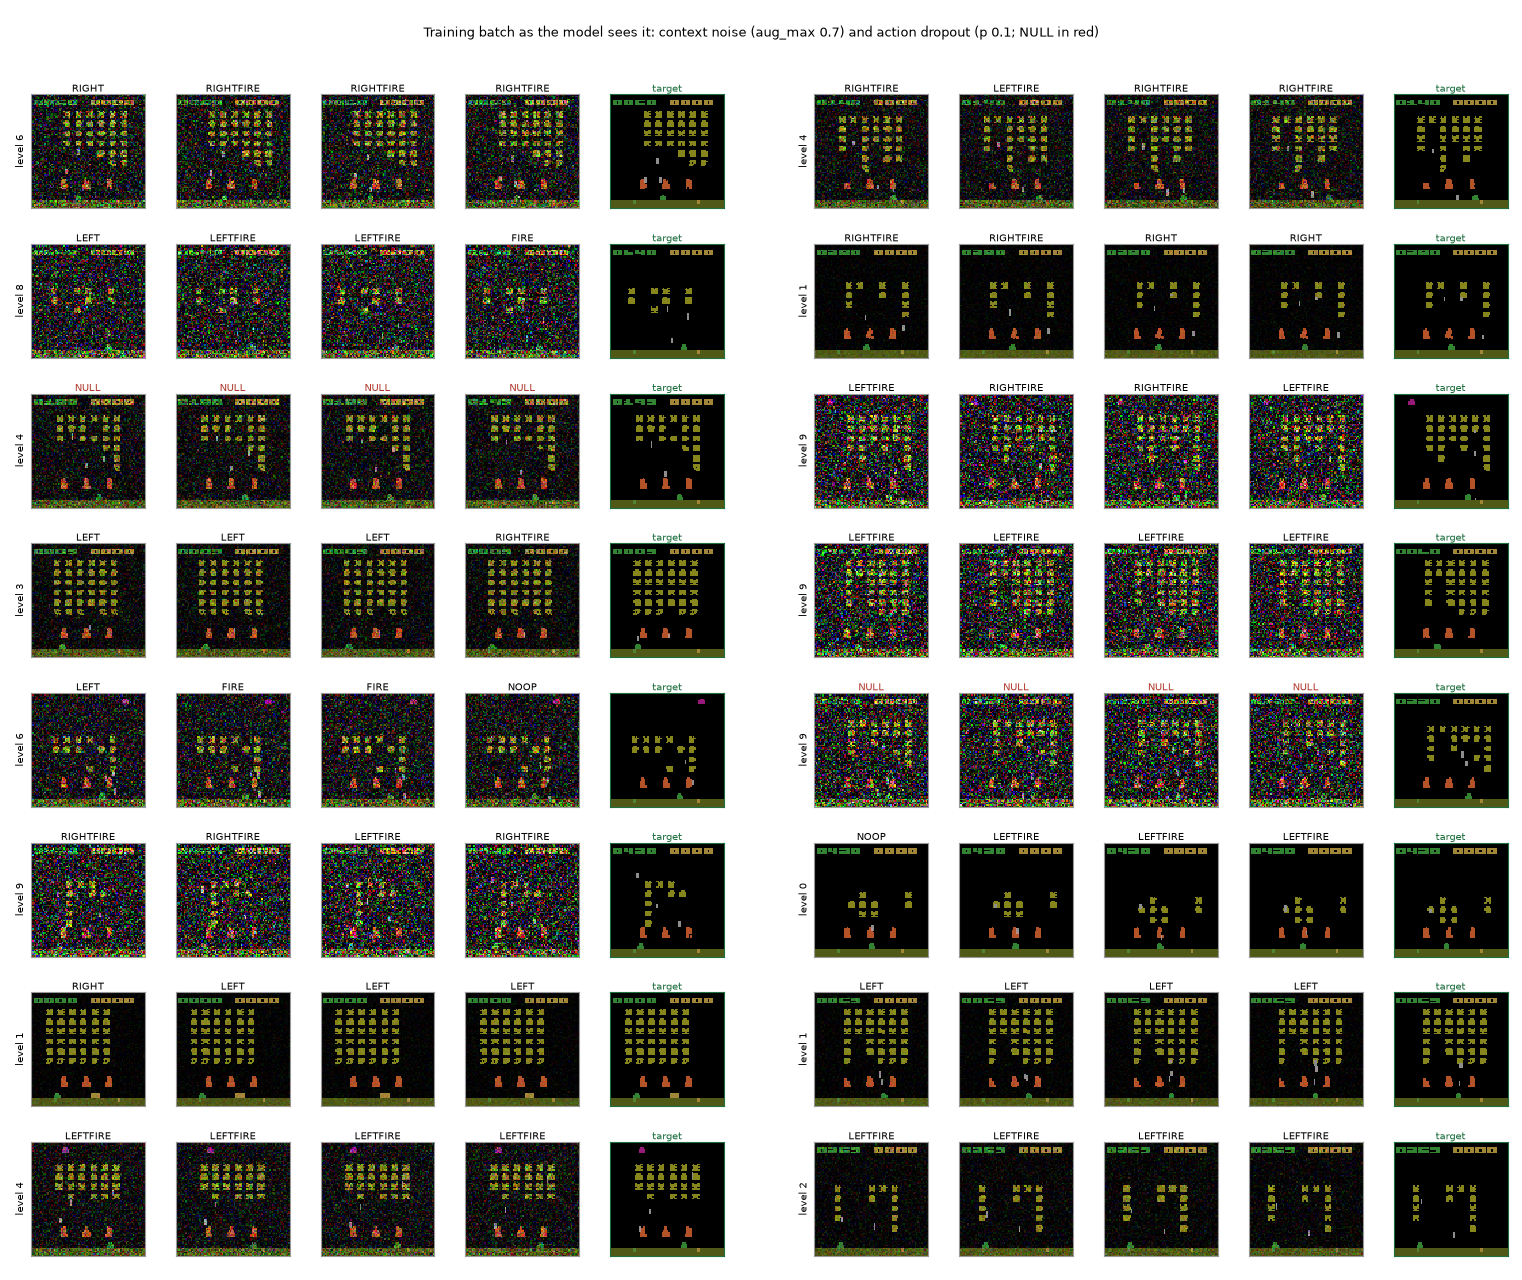

In [6]:
if RUN_CHECKS and HAVE_DEBUG:
    import m2_checks
    from wm.train.trainer import load_run_config
    out = RESULTS / "e1"
    e1 = m2_checks.run_e1(load_run_config("configs/train/debug_aug.yaml", ["data.num_workers=0"]), out)
    (out / "result.json").write_text(json.dumps(e1, indent=2))
e1 = load("e1/result.json")
err = max(abs(s - t) / t for s, t in zip(e1["train_noise_std"], e1["train_sigma_aug"]) if t > 0)
ok = lambda b: "pass" if b else "FAIL"
table(["check", "result", "status"], [
    ["windows equal a direct HDF5 read of their rows (frames and actions), inside one episode",
     f"train {e1['train_windows_match_shard']}/{e1['n']}, val {e1['val_windows_match_shard']}/{e1['n']}",
     ok(e1['train_windows_match_shard'] == e1['val_windows_match_shard'] == e1['n'])],
    ["measured context noise std vs σ_aug of its level", f"max relative error {err:.1%}", ok(err < 0.05)],
    ["action dropout (all 4 actions NULL)", f"{e1['train_dropped_actions']} of {e1['n']} samples (p = 0.1)", "pass"],
    ["val batch: clean context, level 0", f"{e1['val_context_clean']}, {e1['val_ctx_levels_all_zero']}",
     ok(e1['val_context_clean'] and e1['val_ctx_levels_all_zero'])],
    ["value range: targets / noisy context", f"[{e1['target_range'][0]:.2f}, {e1['target_range'][1]:.2f}] / "
     f"[{e1['train_range'][0]:.1f}, {e1['train_range'][1]:.1f}]", "pass"],
])
display(Image(filename=str(RESULTS / "e1/train_batch.png"), width=950))

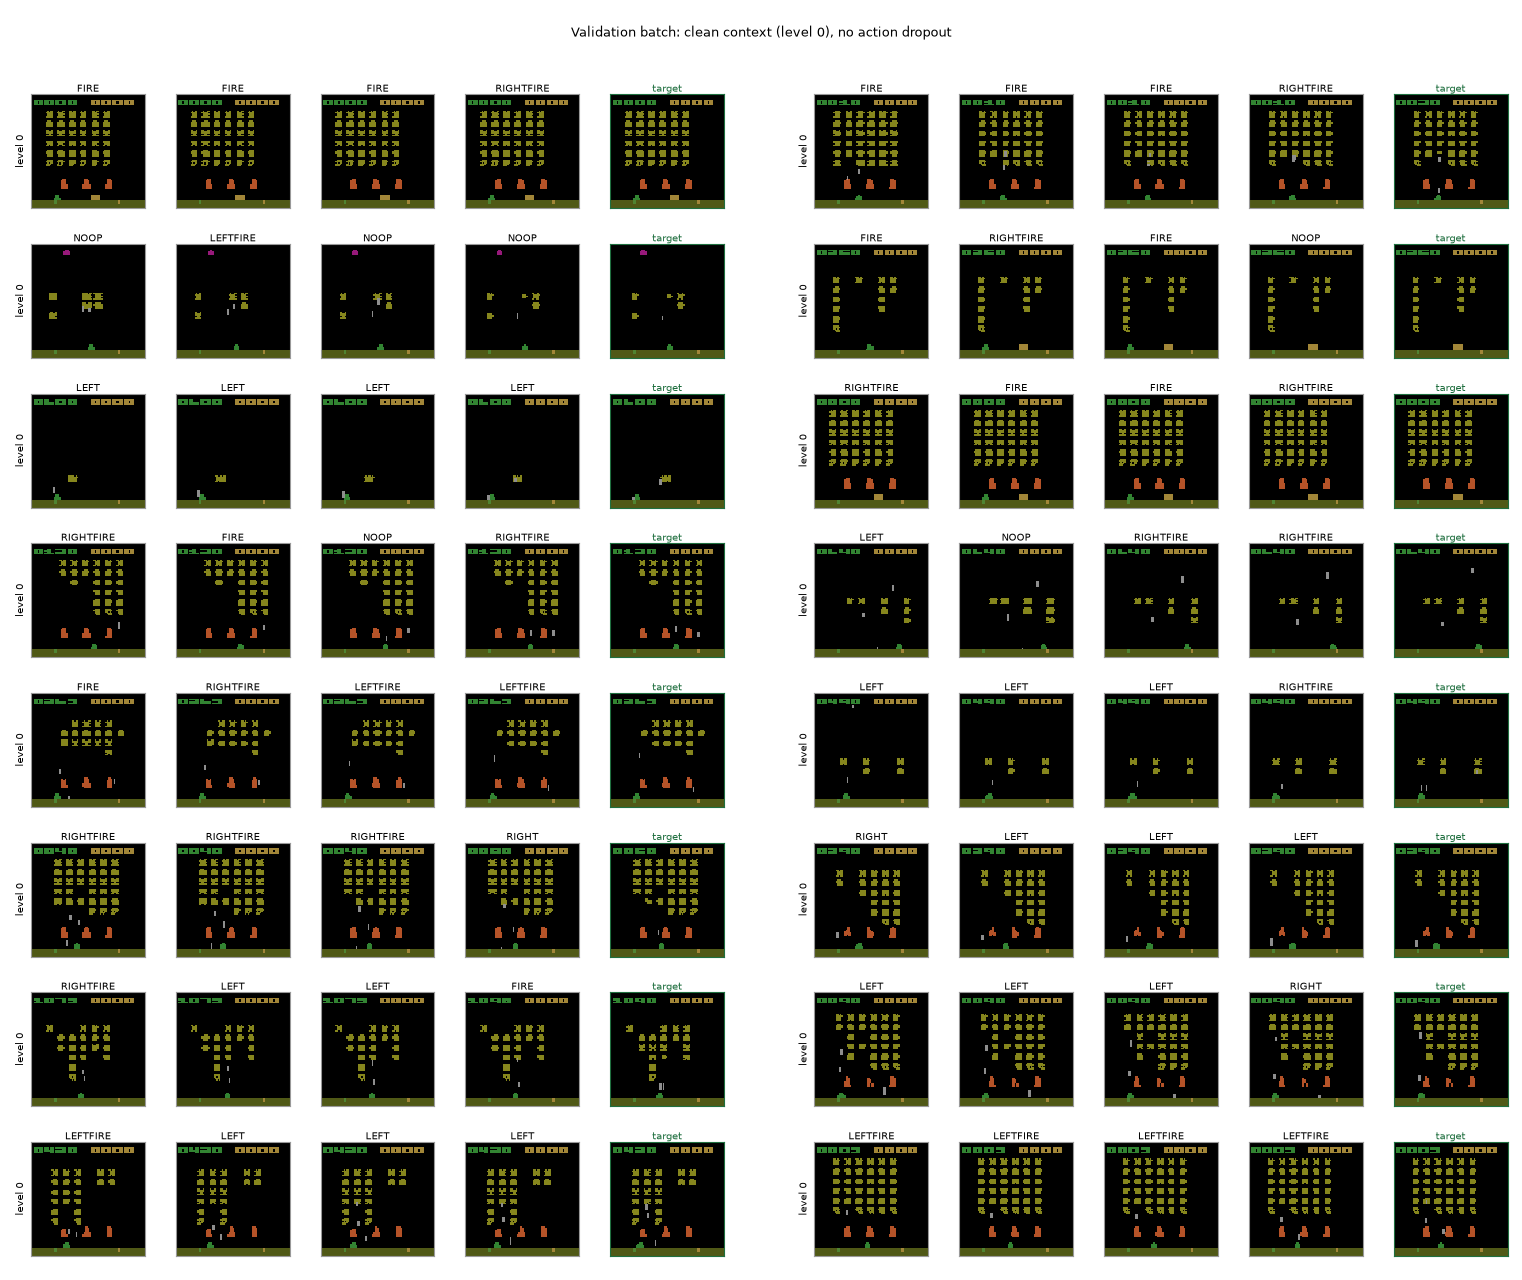

In [7]:
display(Image(filename=str(RESULTS / "e1/val_batch.png"), width=950))

The target frame at the noise levels the denoiser is trained on. EDM adds Gaussian noise of standard deviation σ
to the clean target (in [-1, 1]); training draws ln σ ~ N(-0.4, 1.2²), clamped to [0.002, 20]. At the median
(σ = 0.67) the sprites are still visible; from σ ≈ 2.5 the frame is pure noise.

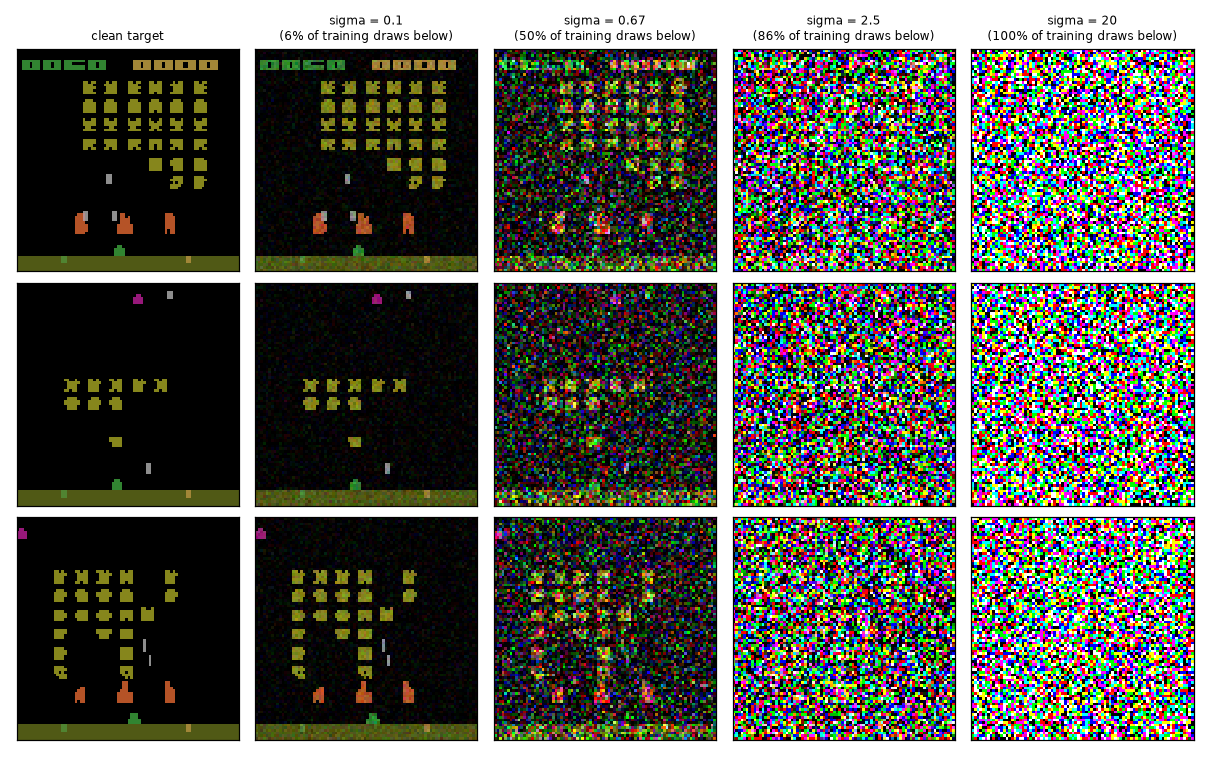

In [8]:
if RUN_CHECKS and HAVE_DEBUG:
    import math
    import matplotlib.pyplot as plt
    from wm.data.dataset import WindowDataset
    ds = WindowDataset(["data/debug"], K=4, split="train")
    g = torch.Generator().manual_seed(SEED)
    idx = torch.randint(len(ds), (3,), generator=g).tolist()
    sigmas, p_mean, p_std = [0.0, 0.1, math.exp(-0.4), 2.5, 20.0], -0.4, 1.2
    below = lambda s: 0.5 * (1 + math.erf((math.log(s) - p_mean) / (p_std * math.sqrt(2))))
    fig, axes = plt.subplots(len(idx), len(sigmas), figsize=(2.2 * len(sigmas), 2.3 * len(idx)), facecolor="white")
    for r, i in enumerate(idx):
        y = ds[i]["target"]
        for c, s in enumerate(sigmas):
            x = (y + s * torch.randn(y.shape, generator=g)).clamp(-1, 1)  # clamped for display only
            axes[r, c].imshow(((x.permute(1, 2, 0) + 1) * 127.5).byte().numpy(), interpolation="nearest")
            axes[r, c].set_xticks([]), axes[r, c].set_yticks([])
            if r == 0:
                axes[r, c].set_title("clean target" if s == 0 else f"sigma = {s:.2g}\n({below(s):.0%} of training draws below)",
                                     fontsize=8)
    plt.tight_layout()
    plt.savefig(RESULTS / "e1/noise_levels.png", dpi=110)
    plt.close(fig)
display(Image(filename=str(RESULTS / "e1/noise_levels.png"), width=900))

Findings:
- The inputs and labels (here: the actions and the target frame) are right. All 32 windows equal an independent
  `h5py` read of their rows, the 4 actions are the ones stored at the 4 context frames, and no window crosses an
  episode boundary. In the images the ship moves the way the actions say (for example, LEFT four times keeps it at
  the left wall).
- Frames are in [-1, 1] and targets are always clean. Noisy contexts go outside that range (-4.1 to 3.7), which is
  intended: the noise is not clamped.
- The measured noise std matches σ_aug at every level. At level 9 (σ = 0.7) the scene is heavily corrupted, but
  the sprites are still visible. Two samples show action dropout (`NULL`).

### E2: initial loss
The guide expects a loss of about 1 for diffusion. Our first logged losses were about 2.4, so we derived the
expected value. The U-Net's output layer is zero-initialised, so at step 0 the network outputs F = 0 and the EDM
loss is E[F_target²] with F_target = (y − c_skip·x)/c_out. For a target y and noise level σ (σ_d = σ_data = 0.5):

$$\mathbb{E}[\text{loss} \mid \sigma] = \frac{\mathbb{E}[y^2]\,\sigma^2 + \sigma_d^4}{\sigma_d^2(\sigma^2+\sigma_d^2)}$$

This is 1 only when E[y²] = σ_d² = 0.25. Space Invaders frames are mostly black (-1 in our scaling), so E[y²] is
about 0.86 and the expected loss, averaged over the training σ distribution, is about 2.4.

| quantity | value |
|---|---|
| largest absolute output F of the fresh network | 0.0 |
| pixel mean, E[y²] of the batch | -0.877, 0.861 (σ_data² = 0.25) |
| expected initial loss (formula) | 2.415 |
| measured, fresh model, 64 σ/noise draws | 2.417 ± 0.026 |
| first logged loss (one draw) | 2.471 |

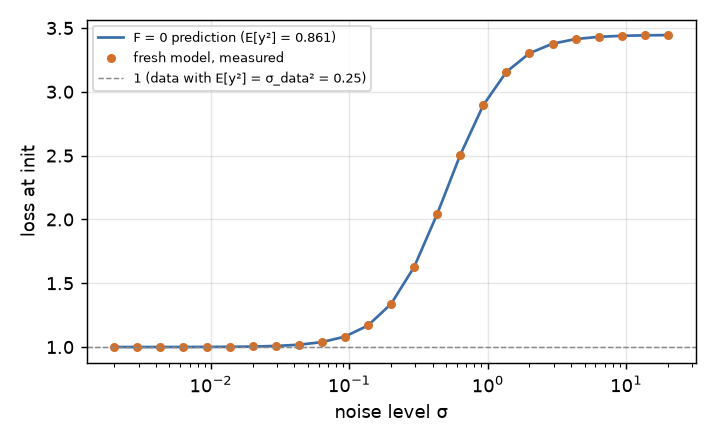

In [9]:
if RUN_CHECKS and HAVE_DEBUG:
    import m2_checks
    from wm.train.trainer import load_run_config
    out = RESULTS / "e2"
    e2 = m2_checks.run_e2(load_run_config("configs/train/debug.yaml", ["data.num_workers=0"]), out)
    (out / "result.json").write_text(json.dumps(e2, indent=2))
e2 = load("e2/result.json")
se = e2["loss_std_over_draws"] / np.sqrt(e2["draws"])
table(["quantity", "value"], [
    ["largest absolute output F of the fresh network", e2["max_abs_F_at_init"]],
    ["pixel mean, E[y²] of the batch", f"{e2['mean_y']:.3f}, {e2['mean_y2']:.3f} (σ_data² = 0.25)"],
    ["expected initial loss (formula)", f"{e2['expected_loss_F0']:.3f}"],
    [f"measured, fresh model, {e2['draws']} σ/noise draws", f"{e2['loss_mean_over_draws']:.3f} ± {1.96 * se:.3f}"],
    ["first logged loss (one draw)", f"{e2['first_batch_loss']:.3f}"],
])
display(Image(filename=str(RESULTS / "e2/initial_loss_vs_sigma.png"), width=600))

Result: passed. The measured initial loss matches the derived value within its 95% CI, and the formula matches the
fresh model at every noise level (plot). The value is 2.4 rather than 1 because our pixel statistics differ from
EDM's assumption, not because of a bug.

This has a consequence for training: with σ_data = 0.5 the EDM loss weighting is not balanced for our data
(large-σ terms get up to E[y²]/σ_d² ≈ 3.4× more weight). So we tried σ_data = 0.93, the measured RMS, as experiment
X3 in E8.

### E3: overfit one batch
A fresh `small` U-Net (14.3M parameters, the R0 architecture) trained on 32 fixed training windows with Adam at
10⁻³, without dropout, weight decay, augmentation or action dropout. The diffusion loss draws a new σ and new noise
every step, so it is noisy. We therefore also track the loss on 4 fixed σ/noise draws, and the PSNR of 2-step
samples against the 32 targets, which plays the role of "100% accuracy".

| step | training loss (one draw) | loss, fixed draws | PSNR of samples (dB) |
|---|---|---|---|
| 0 | - | 2.4103 | 6.7 |
| 250 | 0.2185 | 0.2403 | 25.2 |
| 500 | 0.0222 | 0.0301 | 29.5 |
| 750 | 0.0154 | 0.0263 | 31.4 |
| 1000 | 0.0117 | 0.0178 | 32.8 |
| 1250 | 0.0064 | 0.0091 | 34.9 |
| 1500 | 0.0076 | 0.0104 | 35.5 |
| 1750 | 0.0071 | 0.0103 | 34.9 |
| 2000 | 0.0036 | 0.0057 | 36.5 |

2000 steps on mps in 60.7 min


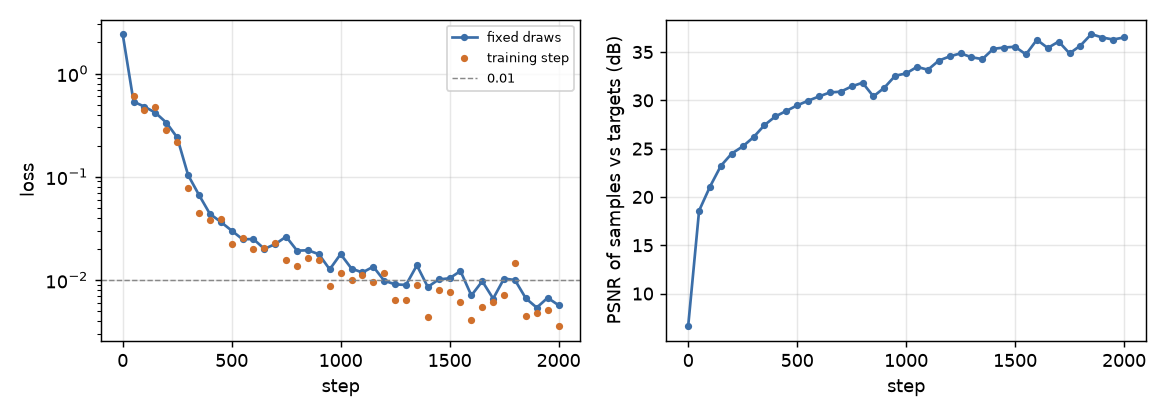

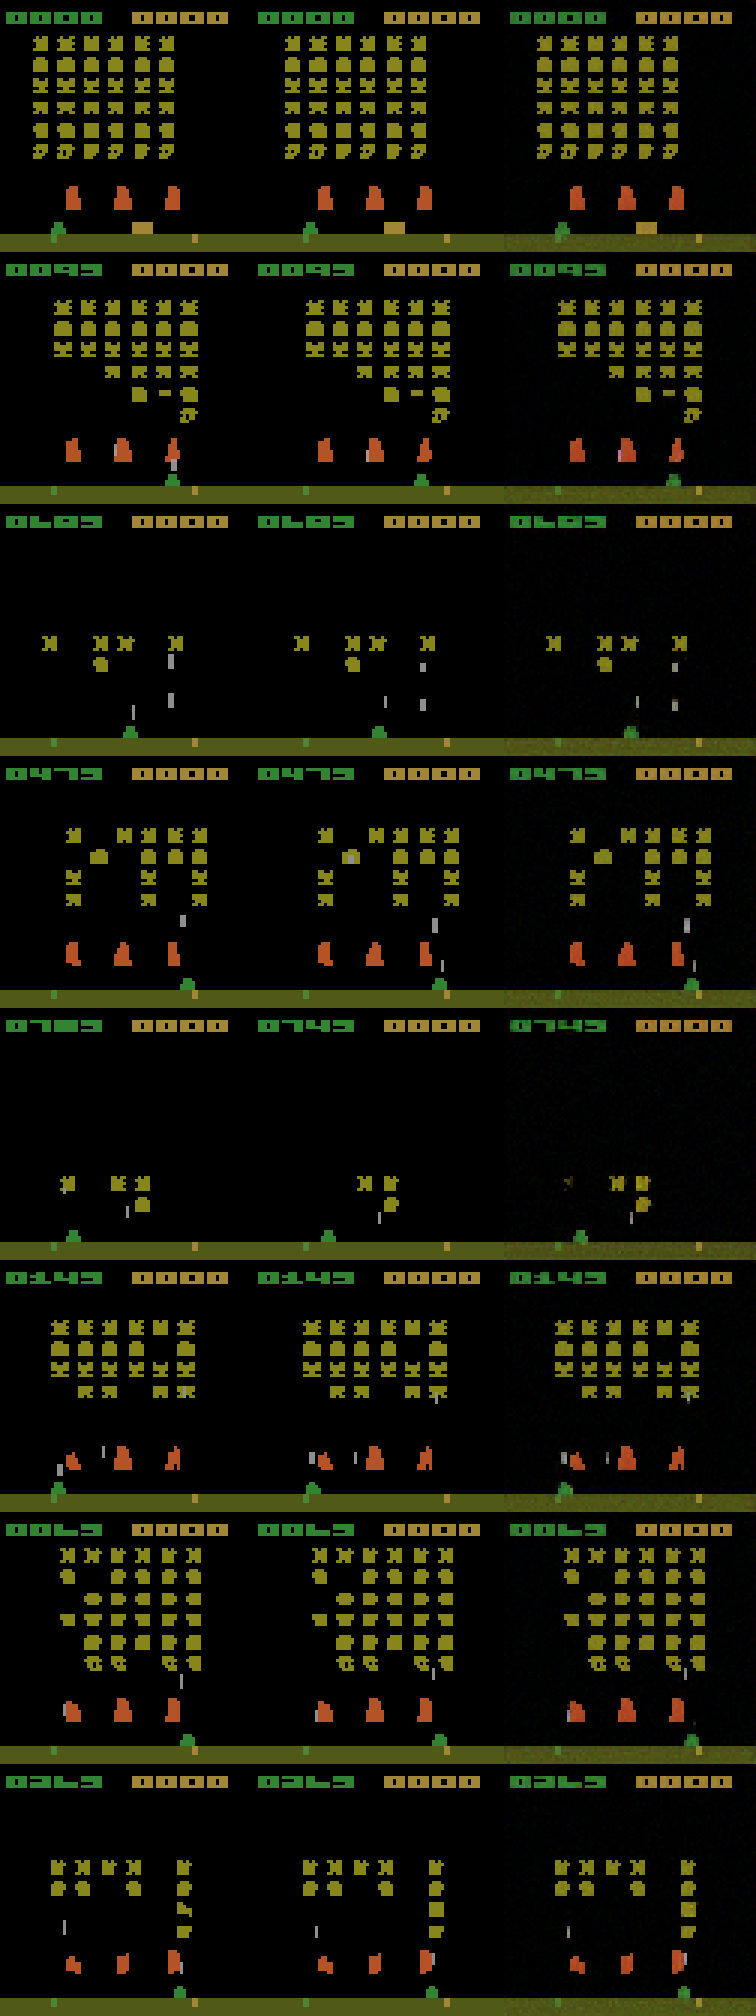

In [10]:
if RUN_CHECKS and HAVE_DEBUG:
    import m2_checks
    from wm.train.trainer import load_run_config
    out = RESULTS / "e3"
    e3 = m2_checks.run_e3(load_run_config("configs/train/debug.yaml", ["data.num_workers=0"]), out, steps=2000)
    (out / "result.json").write_text(json.dumps(e3, indent=2))
e3 = load("e3/result.json")
table(["step", "training loss (one draw)", "loss, fixed draws", "PSNR of samples (dB)"],
      [[r["step"], "-" if r["train_loss"] is None else f"{r['train_loss']:.4f}", f"{r['fixed_loss']:.4f}",
        f"{r['psnr']:.1f}"] for r in e3["log"] if r["step"] % 250 == 0])  # logged every 50
print(f"{e3['steps']} steps on {e3['device']} in {e3['seconds'] / 60:.1f} min")
display(Image(filename=str(RESULTS / "e3/overfit_curve.png"), width=700))
display(Image(filename=str(RESULTS / "e3/overfit_grid.png"), width=420))

Result: passed. The model memorizes the batch, and the loss on fixed draws goes below 0.01.
- 2,000 steps took 61 min on an Apple M4 (MPS). The loss on fixed draws fell from 2.41 (the E2 value) to 0.0057,
  about 420× lower. It first went below 0.01 at step 1,200 and stayed below it from step 1,800 on (0.0100, 0.0066,
  0.0054, 0.0067, 0.0057). Sample PSNR against the targets rose from 6.7 dB (noise) to 36.5 dB.
- In the grid (last context | target | 2-step sample) the samples reproduce each window's layout, score digits,
  bullets, shields and ship position. One alien that the target has already lost is still a faint smudge, and
  some faint background speckle remains.
- There is no sign of a training-loop bug: the loss falls steadily from the expected starting value and nothing gets
  stuck or turns NaN. It takes longer to reach zero than a classifier would, because every step draws a new noise
  level, and at small σ the model has to predict the added noise exactly.

### E4: refresh the baselines on full data
2,048 evenly spaced `data/full` val windows, out of the 249,522 whose target is at step 60 or later. Every model
uses EMA weights, sampler seed 0 and its own default sampler (Euler with 3 steps for the M1 checkpoint, 2 for the
others). Copy-last, which repeats the last context frame, is the trivial baseline and was also our M1 baseline.
Every model is reported as its gap to copy-last on the same windows.

In [11]:
rows = []
for name, label in [("copy_last", "copy-last (floor)"), ("m1", "M1 model (small, 20k steps, debug data)"),
                    ("r0", "R0 (small, 50k steps, full data)"), ("final", "CP5 final (base, aug, 200k steps)")]:
    s = single_step(name)
    rows.append([label] + [f"{s[m]['mean']:.4f} ± {s[m]['ci95']:.4f}" for m in ("psnr", "ssim", "lpips")]
                + ["" if name == "copy_last" else f"{s[m]['mean'] - cl[m]['mean']:+.4f}" for m in ("psnr", "ssim", "lpips")])
table(["model", "PSNR (dB)", "SSIM", "LPIPS", "Δ PSNR", "Δ SSIM", "Δ LPIPS"], rows)
print(f"copy-last: {cl['psnr']['capped_fraction']:.1%} of windows have a target identical to the last context frame "
      "(PSNR capped at 100 dB)")

| model | PSNR (dB) | SSIM | LPIPS | Δ PSNR | Δ SSIM | Δ LPIPS |
|---|---|---|---|---|---|---|
| copy-last (floor) | 34.1404 ± 0.6916 | 0.9657 ± 0.0016 | 0.0116 ± 0.0006 |  |  |  |
| M1 model (small, 20k steps, debug data) | 34.1053 ± 0.2021 | 0.7344 ± 0.0026 | 0.0085 ± 0.0006 | -0.0351 | -0.2313 | -0.0032 |
| R0 (small, 50k steps, full data) | 35.5674 ± 0.2251 | 0.8164 ± 0.0021 | 0.0089 ± 0.0006 | +1.4270 | -0.1493 | -0.0028 |
| CP5 final (base, aug, 200k steps) | 40.6187 ± 0.3732 | 0.9371 ± 0.0015 | 0.0065 ± 0.0006 | +6.4783 | -0.0286 | -0.0051 |

copy-last: 5.1% of windows have a target identical to the last context frame (PSNR capped at 100 dB)


Result:
- Copy-last scores 34.14 dB because consecutive frames are nearly identical. 5.1% of the windows don't change at
  all (PSNR capped at 100 dB), which raises its mean. Its SSIM (0.966) is the highest of all models, because SSIM
  rewards getting the static background exactly right.
- The M1 model only ties copy-last on PSNR (-0.04 dB), but its LPIPS is 27% lower, so it does get the moving
  objects right. Its low SSIM (0.73) comes from background speckle with the 3-step sampler (see Milestone 1).
- R0, the same architecture trained on the full data for 50k steps and sampled with 2 steps, is 1.4 dB above
  copy-last with 24% lower LPIPS.
- The CP5 final model is 6.5 dB above copy-last with 44% lower LPIPS. It is the only model close to copy-last on
  SSIM (-0.03).
- PSNR and LPIPS show what a model adds beyond copying; SSIM mostly rewards copying.

### E5: leakage and shuffle control
Leakage is covered in section 2.

For the shuffle control (placebo) we trained R0 with `train.shuffle_actions=true`: every training sample gets the
action sequence of another sample in its batch, and nothing else changes. Our "labels" are the actions, so if the
controllability metrics work, the placebo should fall to chance while R0 stays well above it.

The metrics come from the CP5 counterfactual evaluation:
- 64 branch points in `data/eval`. From each one, the real emulator and every model play 30 steps of constant LEFT,
  NOOP or RIGHT, each with and without FIRE.
- Ordered: the ship ends up at x(LEFT) < x(NOOP) < x(RIGHT), with a 2 px margin, at the last step. This is counted
  on the 36 branches where the real game is ordered; on the others a life loss respawns the ship at the left wall.
- Δx: the ship's mean movement per step under each program.
- Fire response: a laser is launched within 3 steps while FIRE is held and no laser is in flight. The no-fire
  control measures the same thing without FIRE.
- IDM: how often an inverse dynamics model recovers the program's move and fire from consecutive generated frames.

In [12]:
rows = []
for name, label in [("real", "real emulator"), ("copy_last", "copy-last"), ("r0", "R0 seed 0"), ("r0_seed1", "R0 seed 1"),
                    ("r0_seed2", "R0 seed 2"), ("placebo", "placebo (shuffled actions)")]:
    c, dx = cfr[name], cfr[name]["dx_per_step"]
    rows.append([label, "36" if name == "real" else n_ordered(c)] + [f"{dx[a]:+.3f}" for a in ("LEFT", "NOOP", "RIGHT")]
                + [f"{c['fire_response']['p']:.3f}", f"{c['no_fire_response']['p']:.3f}",
                   f"{c['idm']['move']:.3f}", f"{c['idm']['fire']:.3f}"])
table(["source", "ordered (of 36)", "Δx LEFT", "Δx NOOP", "Δx RIGHT", "fire response", "no-fire control",
       "IDM move", "IDM fire"], rows)

| source | ordered (of 36) | Δx LEFT | Δx NOOP | Δx RIGHT | fire response | no-fire control | IDM move | IDM fire |
|---|---|---|---|---|---|---|---|---|
| real emulator | 36 | -0.614 | -0.250 | +0.267 | 0.625 | 0.062 | 0.689 | 0.575 |
| copy-last | 0 | +0.000 | +0.000 | +0.000 | 0.062 | 0.062 | 0.333 | 0.500 |
| R0 seed 0 | 29 | -0.424 | -0.044 | +0.391 | 0.490 | 0.062 | 0.683 | 0.568 |
| R0 seed 1 | 34 | -0.389 | -0.018 | +0.446 | 0.599 | 0.062 | 0.695 | 0.572 |
| R0 seed 2 | 35 | -0.349 | -0.026 | +0.414 | 0.557 | 0.062 | 0.689 | 0.565 |
| placebo (shuffled actions) | 0 | +0.029 | -0.008 | +0.041 | 0.156 | 0.156 | 0.332 | 0.499 |

Result: the control works. The placebo is at chance on every action metric, and R0 is far above it.
- Placebo: it orders 0 of 36 branches (the R0 seeds order 29, 34 and 35). Its ship barely moves under any program
  (|Δx| ≤ 0.04 px per step). It fires as often without FIRE as with it (0.156 both times), so its shots ignore the
  action. Its IDM move accuracy is 0.33, the same as copy-last and the chance rate for 3 classes.
- R0: the ship moves the right way (Δx LEFT -0.35 to -0.42 and RIGHT +0.39 to +0.45 px per step, against the real
  game's -0.61 and +0.27), and it fires on command (0.49-0.60 against a no-fire control of 0.06; the real game
  gives 0.625).
- Single-step and rollout metrics barely see the difference. The placebo is only 1.0 dB below R0 on single-step PSNR
  and within seed noise on rollouts, because actions change only a few pixels per step. Whether a world model
  follows its inputs has to be measured directly; PSNR and LPIPS cannot show it.

## 4. Experiments (E6-E8)
Every run is `configs/train/debug.yaml` on `data/full` with one change. R0 is:
- the `small` U-Net (14.3M parameters), K = 4
- batch 64, 50k steps, AdamW with lr 10⁻⁴ (1k warmup steps, weight decay 0.01), gradient clipping at 1.0, EMA 0.999
- action dropout 0.1, no context noise, seed 0

Each run used one L40S GPU on Dartmouth College's GPU cluster: about 2.3 h for `small`, longer for `base`. They were submitted with
`scripts/slurm/m2_runs.sh train` and all evaluated the same way with `posteval`:
- Single-step: the E4 windows.
- Rollouts: 64 `data/eval` trajectories starting at step 32, 200 generated frames driven by the recorded actions,
  Euler with 2 steps, context level 0.
- Counterfactuals: as in E5.

E7 comes first because it sets how large a difference has to be to count.

### E7: seeds and the smallest meaningful difference
R0 was trained 3 times (seeds 0, 1, 2 change the weight init, data order and noise draws). The smallest meaningful
difference is the larger of 2 × the std over seeds and the largest 95% CI half-width of a single run. Differences
below it count as no effect.

In [13]:
def _single(m):
    return lambda n: (single_step(n)[m]["mean"], single_step(n)[m]["ci95"])

def _roll(m, h):
    return lambda n: (rollout(n)[m][str(h)]["mean"], rollout(n)[m][str(h)]["ci95"])

METRICS = {  # label: (getter returning (mean, ci95), higher is better)
    "single-step PSNR (dB)": (_single("psnr"), True),
    "single-step SSIM": (_single("ssim"), True),
    "single-step LPIPS": (_single("lpips"), False),
    "rollout PSNR h=20 (dB)": (_roll("psnr", 20), True),
    "rollout PSNR h=50 (dB)": (_roll("psnr", 50), True),
    "rollout LPIPS h=200": (_roll("lpips", 200), False),
    "ordered branches (of 36)": (lambda n: (n_ordered(cfr[n]), 0.0), True),
}

def seed_stats(get):
    """Mean and std over the R0 seeds, and the smallest meaningful difference."""
    v = np.array([get(s)[0] for s in SEEDS])
    return v.mean(), v.std(ddof=1), max(2 * v.std(ddof=1), max(get(s)[1] for s in SEEDS))

STATS = {label: seed_stats(get) for label, (get, _) in METRICS.items()}
table(["metric", "seed 0", "seed 1", "seed 2", "mean", "std", "smallest meaningful difference"],
      [[label] + [f"{get(s)[0]:.4g}" for s in SEEDS] + [f"{v:.4g}" for v in STATS[label]]
       for label, (get, _) in METRICS.items()])

| metric | seed 0 | seed 1 | seed 2 | mean | std | smallest meaningful difference |
|---|---|---|---|---|---|---|
| single-step PSNR (dB) | 35.57 | 36.17 | 35.63 | 35.79 | 0.331 | 0.662 |
| single-step SSIM | 0.8164 | 0.8461 | 0.819 | 0.8272 | 0.01645 | 0.0329 |
| single-step LPIPS | 0.008871 | 0.008113 | 0.008293 | 0.008426 | 0.0003958 | 0.0007916 |
| rollout PSNR h=20 (dB) | 20.19 | 20.77 | 21.56 | 20.84 | 0.6873 | 1.375 |
| rollout PSNR h=50 (dB) | 16.36 | 16.93 | 17.43 | 16.91 | 0.5349 | 1.07 |
| rollout LPIPS h=200 | 0.2131 | 0.1862 | 0.1754 | 0.1916 | 0.01938 | 0.03876 |
| ordered branches (of 36) | 29 | 34 | 35 | 32.67 | 3.215 | 6.429 |

Result:
- Seed noise is larger than the per-run CI. For single-step PSNR the three seeds span 0.6 dB (35.57 to 36.17),
  while one run's 95% CI is only ±0.23 dB. A single run would overstate how sure we are, so on every metric the
  threshold comes from the seeds.
- Ordering varies the most between seeds (29 to 35 of 36 branches), so an experiment has to move it by about 6
  branches to count.

### E6: data-size curve
R0 trained on 12.5%, 25%, 50% and 100% of the `data/full` training episodes, with the same steps, batch and val
windows.
- `data/full` was written by 16 collection workers per play style. Each subset keeps the shards of the first 2, 4
  or 8 workers of every style, so the play-style mix is exact and each smaller subset is contained in the larger
  ones. We used 12.5% instead of 10% because 10% can't be split evenly over 16 workers.
- The subset directories link the original shards under their original names, so every episode stays in its
  train/val split.
- The 100% point is the mean of the three R0 seeds, and the bar shows their range.

| train episodes | single-step Δ PSNR vs copy-last (dB) | single-step LPIPS | rollout Δ PSNR vs copy-last, h=50 (dB) | rollout LPIPS h=200 | ordered (of 36) |
|---|---|---|---|---|---|
| 12.5% | +2.07 | 0.0083 | +1.59 | 0.183 | 35 |
| 25% | +1.69 | 0.0085 | +0.99 | 0.200 | 36 |
| 50% | +1.42 | 0.0085 | +1.14 | 0.193 | 36 |
| 100% (3 seeds) | +1.65 | 0.0084 | +1.38 | 0.192 | 32.7 |

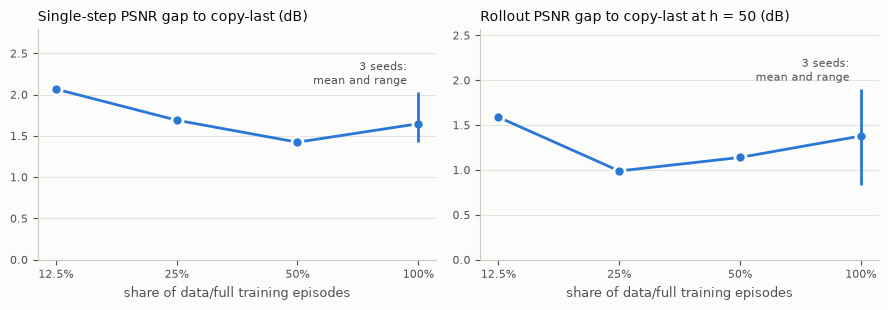

In [14]:
import matplotlib.pyplot as plt

FRACTIONS = [("data_p12", 12.5), ("data_p25", 25), ("data_p50", 50)]
cl_roll = rollout("copy_last")
gap_ss = lambda n: single_step(n)["psnr"]["mean"] - cl["psnr"]["mean"]
gap_h50 = lambda n: rollout(n)["psnr"]["50"]["mean"] - cl_roll["psnr"]["50"]["mean"]
rows = [[f"{f:g}%", f"{gap_ss(n):+.2f}", f"{single_step(n)['lpips']['mean']:.4f}", f"{gap_h50(n):+.2f}",
         f"{rollout(n)['lpips']['200']['mean']:.3f}", n_ordered(cfr[n])] for n, f in FRACTIONS]
seed_mean = lambda f: np.mean([f(s) for s in SEEDS])
rows.append(["100% (3 seeds)", f"{seed_mean(gap_ss):+.2f}", f"{seed_mean(lambda s: single_step(s)['lpips']['mean']):.4f}",
             f"{seed_mean(gap_h50):+.2f}", f"{seed_mean(lambda s: rollout(s)['lpips']['200']['mean']):.3f}",
             f"{seed_mean(lambda s: n_ordered(cfr[s])):.1f}"])
table(["train episodes", "single-step Δ PSNR vs copy-last (dB)", "single-step LPIPS",
       "rollout Δ PSNR vs copy-last, h=50 (dB)", "rollout LPIPS h=200", "ordered (of 36)"], rows)

# One measure per panel, one series each: no legend needed, the panel titles name the measure.
INK, MUTED, SERIES = "#0b0b0b", "#52514e", "#2a78d6"
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), facecolor="#fcfcfb")
for ax, f, title in [(axes[0], gap_ss, "Single-step PSNR gap to copy-last (dB)"),
                     (axes[1], gap_h50, "Rollout PSNR gap to copy-last at h = 50 (dB)")]:
    x = [p for _, p in FRACTIONS] + [100]
    seeds = [f(s) for s in SEEDS]
    y = [f(n) for n, _ in FRACTIONS] + [np.mean(seeds)]
    ax.plot(x, y, color=SERIES, linewidth=2, marker="o", markersize=8, markeredgecolor="#fcfcfb", markeredgewidth=2)
    ax.vlines(100, min(seeds), max(seeds), color=SERIES, linewidth=2)
    ax.annotate("3 seeds:\nmean and range", (100, max(seeds)), xytext=(-8, 6), textcoords="offset points",
                ha="right", fontsize=8, color=MUTED)
    ax.set_xscale("log", base=2)
    ax.set_xticks(x, [f"{v:g}%" for v in x])
    ax.set_xlabel("share of data/full training episodes", color=MUTED, fontsize=9)
    ax.set_title(title, color=INK, fontsize=10, loc="left")
    ax.set_ylim(0, max(y + seeds) * 1.35)
    ax.set_facecolor("#fcfcfb")
    ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
    ax.tick_params(colors=MUTED, labelsize=8)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color("#c9c8c2")
plt.tight_layout()
plt.show()

Result: the curve is flat.
- No metric changes by more than the E7 threshold between 12.5% and 100% of the data. 12.5% is nominally best on
  single-step and rollout PSNR, but within seed noise.
- The reason is the training budget. 50k steps at batch 64 is 3.2M windows. The 12.5% subset (about 0.6M windows)
  is seen about 5 times, the full set (4.7M windows) less than once. At this budget the model is limited by
  training time, not by data.
- So the 5M dataset only pays off with longer training. The CP5 final model saw 25.6M windows (200k steps × 128),
  about 5 passes over the full data.

### E8: run log and one-change runs
Every Milestone 2 training run, with what differs from R0. Everything not listed is the R0 setting above.

In [15]:
LOG = [  # (run, purpose, change vs R0)
    ("r0", "R0, E6 100%, E7 seed 0", "-"),
    ("r0_seed1", "E7", "seed 1"),
    ("r0_seed2", "E7", "seed 2"),
    ("placebo", "E5 shuffle control", "train.shuffle_actions = true"),
    ("data_p12", "E6", "12.5% of the training episodes"),
    ("data_p25", "E6", "25% of the training episodes"),
    ("data_p50", "E6", "50% of the training episodes"),
    ("x1_aug", "E8 X1", "context noise augmentation, aug_max 0.7"),
    ("r0_n3", "E8 X2", "no training: R0 seed 0 sampled with 3 Euler steps"),
    ("x3_sigma093", "E8 X3", "edm.sigma_data 0.93"),
    ("x4_base", "E8 X4", "base width, ch [128, 256, 384], 34.4M parameters"),
]
CURVES = RESULTS / "curves"

def val_loss(n):
    """Validation loss at the last logged step, from the exported TensorBoard curves."""
    f = CURVES / f"{n}.json"
    return f"{json.loads(f.read_text())['val']['loss'][-1]:.4f}" if f.exists() else "-"

table(["run", "used for", "change vs R0", "steps", "val loss at end", "single-step PSNR (dB)", "rollout PSNR h=50 (dB)"],
      [[n, purpose, change, "-" if n == "r0_n3" else "50k", "-" if n == "r0_n3" else val_loss(n),
        f"{single_step(n)['psnr']['mean']:.2f}", f"{rollout(n)['psnr']['50']['mean']:.2f}"] for n, purpose, change in LOG])

| run | used for | change vs R0 | steps | val loss at end | single-step PSNR (dB) | rollout PSNR h=50 (dB) |
|---|---|---|---|---|---|---|
| r0 | R0, E6 100%, E7 seed 0 | - | 50k | 0.0012 | 35.57 | 16.36 |
| r0_seed1 | E7 | seed 1 | 50k | 0.0011 | 36.17 | 16.93 |
| r0_seed2 | E7 | seed 2 | 50k | 0.0011 | 35.63 | 17.43 |
| placebo | E5 shuffle control | train.shuffle_actions = true | 50k | 0.0013 | 34.80 | 16.31 |
| data_p12 | E6 | 12.5% of the training episodes | 50k | 0.0010 | 36.21 | 17.12 |
| data_p25 | E6 | 25% of the training episodes | 50k | 0.0011 | 35.83 | 16.52 |
| data_p50 | E6 | 50% of the training episodes | 50k | 0.0011 | 35.56 | 16.67 |
| x1_aug | E8 X1 | context noise augmentation, aug_max 0.7 | 50k | 0.0015 | 36.83 | 23.57 |
| r0_n3 | E8 X2 | no training: R0 seed 0 sampled with 3 Euler steps | - | - | 34.29 | 17.10 |
| x3_sigma093 | E8 X3 | edm.sigma_data 0.93 | 50k | 0.0006 | 32.50 | 16.40 |
| x4_base | E8 X4 | base width, ch [128, 256, 384], 34.4M parameters | 50k | 0.0009 | 35.22 | 17.74 |

The table below compares each change with the mean of the three R0 seeds. X2 is inference only, so it is compared
with R0 seed 0 itself. "better" or "worse" means the difference is larger than the E7 threshold; "no effect" means
it is within seed noise.

In [16]:
CHANGES = [("x1_aug", "X1: context noise augmentation (aug_max 0.7)"), ("r0_n3", "X2: 3 sampler steps instead of 2"),
           ("x3_sigma093", "X3: σ_data = 0.93 (from E2)"), ("x4_base", "X4: base width (34.4M parameters)")]

def get_value(name, label):
    get, _ = METRICS[label]
    if name != "r0_n3":
        return get(name)[0]
    if label.startswith("single-step"):
        return single_step("r0_n3")[{"PSNR": "psnr", "SSIM": "ssim", "LPIPS": "lpips"}[label.split()[1]]]["mean"]
    if label.startswith("rollout"):
        m, h = label.split()[1].lower(), label.split("h=")[1].split()[0]
        return rollout("r0_n3")[m][h]["mean"]
    return None  # no counterfactual run for X2

rows = [["R0 (mean of 3 seeds)"] + [f"{STATS[label][0]:.4g}" for label in METRICS]]
for name, title in CHANGES:
    row = [title]
    for label, (get, higher) in METRICS.items():
        v = get_value(name, label)
        if v is None:
            row.append("-")
            continue
        ref = get("r0")[0] if name == "r0_n3" else STATS[label][0]
        d = v - ref
        mark = "no effect" if abs(d) <= STATS[label][2] else ("better" if (d > 0) == higher else "worse")
        row.append(f"{v:.4g} ({d:+.3g}, {mark})")
    rows.append(row)
table(["run"] + list(METRICS), rows)

| run | single-step PSNR (dB) | single-step SSIM | single-step LPIPS | rollout PSNR h=20 (dB) | rollout PSNR h=50 (dB) | rollout LPIPS h=200 | ordered branches (of 36) |
|---|---|---|---|---|---|---|---|
| R0 (mean of 3 seeds) | 35.79 | 0.8272 | 0.008426 | 20.84 | 16.91 | 0.1916 | 32.67 |
| X1: context noise augmentation (aug_max 0.7) | 36.83 (+1.04, better) | 0.8901 (+0.0629, better) | 0.008034 (-0.000392, no effect) | 25.31 (+4.47, better) | 23.57 (+6.66, better) | 0.09341 (-0.0982, better) | 35 (+2.33, no effect) |
| X2: 3 sampler steps instead of 2 | 34.29 (-1.27, worse) | 0.727 (-0.0893, worse) | 0.008311 (-0.00056, no effect) | 20.66 (+0.472, no effect) | 17.1 (+0.736, no effect) | 0.1989 (-0.0141, no effect) | - |
| X3: σ_data = 0.93 (from E2) | 32.5 (-3.29, worse) | 0.6272 (-0.2, worse) | 0.01193 (+0.0035, worse) | 20.04 (-0.798, no effect) | 16.4 (-0.509, no effect) | 0.2054 (+0.0139, no effect) | 33 (+0.333, no effect) |
| X4: base width (34.4M parameters) | 35.22 (-0.569, no effect) | 0.8072 (-0.0199, no effect) | 0.009138 (+0.000713, no effect) | 21.91 (+1.07, no effect) | 17.74 (+0.828, no effect) | 0.1814 (-0.0102, no effect) | 28 (-4.67, no effect) |

Result: context noise augmentation is the only clear improvement.
- X1, context noise, is better on every image metric and has by far the largest effect. Rollout PSNR goes up by
  4.5 dB at h = 20 and 6.7 dB at h = 50, about 6× the seed threshold, and LPIPS at h = 200 halves (0.093 vs 0.192).
  Single-step PSNR and SSIM also improve (+1.0 dB, +0.06), and controllability is unchanged (35/36). CP4 found
  +2.5 dB at h = 20 on the debug data, so the gain is larger at full scale.
- X2, 3 sampler steps, is worse single-step (-1.3 dB PSNR, -0.09 SSIM, because the third step adds background
  speckle) with no rollout gain. We keep 2 steps.
- X3, σ_data = 0.93, is worse single-step (-3.3 dB PSNR, SSIM down to 0.63, LPIPS up 42%), and its rollouts are
  within noise. Balancing the loss at initialisation (E2) does not improve the samples, so σ_data stays at 0.5.
- X4, base width, has no effect within 50k steps: every metric is within noise. Its ordering (28/36) is the lowest of
  the runs but still inside the seed range. Together with E6, this says the 50k-step runs are limited by the
  training budget, not by data or model size.
- The CP5 final model combines base width, context noise, 4× the steps and 2× the batch. These runs can't separate
  those contributions; they only show that context noise helps on its own.

### Learning curves
Training loss (mean per 1,000 steps; logged from one batch every 50 steps) and validation loss on the `data/full`
val split (fixed noise draws, logged every 1,000 steps), from each run's TensorBoard log.

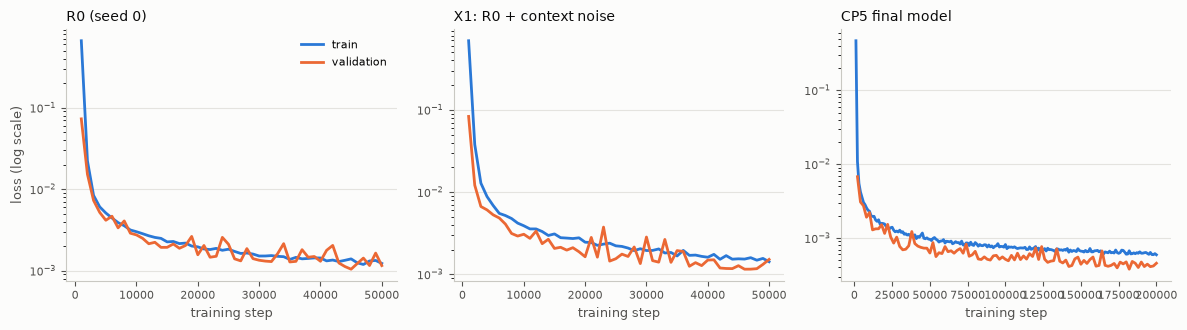

| run | train loss (last 5k steps) | val loss (last 5 evals) | val / train |
|---|---|---|---|
| r0 | 0.0013 | 0.0013 | 1.05 |
| r0_seed1 | 0.0012 | 0.0011 | 0.93 |
| r0_seed2 | 0.0012 | 0.0013 | 1.11 |
| placebo | 0.0014 | 0.0015 | 1.08 |
| data_p12 | 0.0012 | 0.0013 | 1.06 |
| data_p25 | 0.0012 | 0.0013 | 1.06 |
| data_p50 | 0.0012 | 0.0012 | 0.96 |
| x1_aug | 0.0015 | 0.0013 | 0.83 |
| x3_sigma093 | 0.0007 | 0.0007 | 0.99 |
| x4_base | 0.0010 | 0.0010 | 0.94 |
| final | 0.0006 | 0.0004 | 0.70 |

In [17]:
import matplotlib.pyplot as plt

if not CURVES.exists():
    print("Learning curves not exported yet: run `bash scripts/slurm/m2_runs.sh curves` on Dartmouth College's GPU cluster "
          "and copy results/milestone2/curves/ here.")
else:
    INK, MUTED, TRAIN, VAL = "#0b0b0b", "#52514e", "#2a78d6", "#eb6834"
    panels = [("r0", "R0 (seed 0)"), ("x1_aug", "X1: R0 + context noise"), ("final", "CP5 final model")]
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), facecolor="#fcfcfb")
    for ax, (n, title) in zip(axes, panels):
        c = json.loads((CURVES / f"{n}.json").read_text())
        ax.plot(c["train"]["step"], c["train"]["loss"], color=TRAIN, linewidth=2, label="train")
        ax.plot(c["val"]["step"], c["val"]["loss"], color=VAL, linewidth=2, label="validation")
        ax.set_yscale("log")
        ax.set_title(title, color=INK, fontsize=10, loc="left")
        ax.set_xlabel("training step", color=MUTED, fontsize=9)
        ax.set_facecolor("#fcfcfb")
        ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
        ax.tick_params(colors=MUTED, labelsize=8)
        for side in ("top", "right"):
            ax.spines[side].set_visible(False)
        for side in ("left", "bottom"):
            ax.spines[side].set_color("#c9c8c2")
    axes[0].set_ylabel("loss (log scale)", color=MUTED, fontsize=9)
    axes[0].legend(frameon=False, fontsize=8)
    plt.tight_layout()
    plt.show()
    last = lambda c, k, n=5: np.mean(c[k]["loss"][-n:])
    rows = []
    for n in [r for r, _, _ in LOG if r != "r0_n3"] + ["final"]:
        c = json.loads((CURVES / f"{n}.json").read_text())
        rows.append([n, f"{last(c, 'train'):.4f}", f"{last(c, 'val'):.4f}", f"{last(c, 'val') / last(c, 'train'):.2f}"])
    table(["run", "train loss (last 5k steps)", "val loss (last 5 evals)", "val / train"], rows)

Findings:
- Training and validation loss fall fast in the first 5k steps, then slowly. No run's validation loss turns up,
  so nothing overfits, and for the R0-type runs validation stays within about 10% of training loss (val/train 0.93
  to 1.11). With 4.7M training windows and at most 5 passes over the data this is expected.
- The curves are still going down at the end. Over the last fifth of training, validation loss is 8% lower than
  over the fifth before it for R0, 22% for X1 and 12% for the final model (its last 40k steps). This agrees with
  E6: the 50k-step runs are limited by training time, not by data.
- For X1 and the final model, validation loss is below training loss (0.83 and 0.70 of it). The training loss is
  measured on noisy context frames with action dropout; validation uses clean context and all actions.
- Validation is computed with the raw training weights, not the EMA weights we sample with, so it jumps more
  between evaluations than the training mean does.
- The loss does not rank models by what matters. The placebo's loss is only about 15% above R0's although it
  ignores the actions completely, and X3's loss is half of R0's although its samples are 3.3 dB worse (changing
  σ_data changes the loss weighting, so the values are not comparable). This is why every experiment is judged on
  generated frames and controllability rather than on loss.

## 5. Results on the test set
`data/test` has 100 held-out episodes (seeds from 1.5 × 10⁹) and 38,766 windows. It was not used for any choice, and
the models below were evaluated on it once, with the same three evaluations as above:
- Single-step: 2,048 of the 33,166 windows whose target is at step 60 or later.
- Rollouts: 64 trajectories.
- Counterfactuals: 64 branches.

The rows are copy-last (the trivial baseline, which was also our M1 baseline), the M1 model, R0 (all three seeds),
X1 (the best one-change run) and the CP5 final model (`base` width, context noise, 200k steps at batch 128 on
`data/full`). The R0 row shows the mean over seeds with the min and max.

In [18]:
def t_single(name):
    pattern = {"copy_last": "copy_last", "final": "*final*", "m1": "*debug_small*"}.get(name, f"*_m2_{name}_ckpt*")
    return json.loads(sorted(RESULTS.glob(f"test/single_step/{pattern}/metrics.json"))[-1].read_text())["metrics"]

def t_roll(name):
    return next(iter(load(f"test/rollouts/{name}/metrics.json")["models"].values()))["report"]

def cf_key(k):
    return k.split("_m2_")[1].split("_ckpt")[0] if "_m2_" in k else "final" if "final" in k else "m1" if "debug_small" in k else k

t_cf = {cf_key(k): v for k, v in load("test/counterfactual/metrics.json")["results"].items()}
HAVE_M1_TEST = (RESULTS / "test/counterfactual_m1/metrics.json").exists() and (RESULTS / "test/rollouts/m1").exists()
if HAVE_M1_TEST:
    t_cf.update({cf_key(k): v for k, v in load("test/counterfactual_m1/metrics.json")["results"].items() if k != "real"})
t_cl = t_single("copy_last")

COLS = [("single-step Δ PSNR (dB)", lambda n: t_single(n)["psnr"]["mean"] - t_cl["psnr"]["mean"], "{:+.2f}"),
        ("single-step SSIM", lambda n: t_single(n)["ssim"]["mean"], "{:.3f}"),
        ("single-step LPIPS", lambda n: t_single(n)["lpips"]["mean"], "{:.4f}"),
        ("rollout PSNR h=20", lambda n: t_roll(n)["psnr"]["20"]["mean"], "{:.1f}"),
        ("h=50", lambda n: t_roll(n)["psnr"]["50"]["mean"], "{:.1f}"),
        ("h=100", lambda n: t_roll(n)["psnr"]["100"]["mean"], "{:.1f}"),
        ("rollout LPIPS h=50", lambda n: t_roll(n)["lpips"]["50"]["mean"], "{:.3f}"),
        ("h=200", lambda n: t_roll(n)["lpips"]["200"]["mean"], "{:.3f}"),
        ("ordered (of 41)", lambda n: n_ordered(t_cf[n]), "{:.0f}"),
        ("fire response", lambda n: t_cf[n]["fire_response"]["p"], "{:.2f}")]
rows = [["copy-last (trivial and M1 baseline)"] + [fmt.format(f("copy_last")) for _, f, fmt in COLS]]
if HAVE_M1_TEST:
    rows.append(["M1 model (small, 20k steps, debug data)"] + [fmt.format(f("m1")) for _, f, fmt in COLS])
else:
    rows.append(["M1 model: not evaluated yet (m2_runs.sh m1test)"] + [""] * len(COLS))
r0 = [[f(s) for s in SEEDS] for _, f, _ in COLS]
rows.append(["R0 (3 seeds: mean [min, max])"] + [f"{fmt.format(np.mean(v))} [{fmt.format(min(v))}, {fmt.format(max(v))}]"
                                                for v, (_, _, fmt) in zip(r0, COLS)])
rows += [[label] + [fmt.format(f(n)) for _, f, fmt in COLS] for n, label in [("x1_aug", "X1: R0 + context noise"),
                                                                              ("final", "CP5 final model")]]
rows.append(["real emulator"] + [""] * 8 + ["41 of 64 branches ordered", f"{t_cf['real']['fire_response']['p']:.2f}"])
table(["model"] + [c for c, _, _ in COLS], rows)
print(f"copy-last single-step PSNR {t_cl['psnr']['mean']:.2f} dB ({t_cl['psnr']['capped_fraction']:.1%} of windows unchanged); "
      f"rollout PSNR copy-last h=20/50/100: " + "/".join(f"{t_roll('copy_last')['psnr'][h]['mean']:.1f}" for h in ("20", "50", "100")))

| model | single-step Δ PSNR (dB) | single-step SSIM | single-step LPIPS | rollout PSNR h=20 | h=50 | h=100 | rollout LPIPS h=50 | h=200 | ordered (of 41) | fire response |
|---|---|---|---|---|---|---|---|---|---|---|
| copy-last (trivial and M1 baseline) | +0.00 | 0.967 | 0.0087 | 18.5 | 15.7 | 15.8 | 0.083 | 0.230 | 0 | 0.09 |
| M1 model (small, 20k steps, debug data) | -0.43 | 0.770 | 0.0057 | 20.2 | 16.9 | 15.9 | 0.075 | 0.201 | 38 | 0.63 |
| R0 (3 seeds: mean [min, max]) | +1.10 [+0.82, +1.61] | 0.856 [0.844, 0.875] | 0.0063 [0.0061, 0.0066] | 21.0 [20.2, 21.8] | 17.2 [16.6, 17.8] | 15.9 [15.8, 16.0] | 0.074 [0.068, 0.085] | 0.187 [0.168, 0.212] | 39 [38, 40] | 0.62 [0.58, 0.66] |
| X1: R0 + context noise | +2.14 | 0.907 | 0.0064 | 26.6 | 22.8 | 19.7 | 0.032 | 0.095 | 41 | 0.62 |
| CP5 final model | +5.66 | 0.944 | 0.0061 | 32.4 | 23.1 | 18.6 | 0.033 | 0.120 | 41 | 0.66 |
| real emulator |  |  |  |  |  |  |  |  | 41 of 64 branches ordered | 0.67 |

copy-last single-step PSNR 34.63 dB (5.7% of windows unchanged); rollout PSNR copy-last h=20/50/100: 18.5/15.7/15.8


Result: the test set confirms the validation results.
- Single-step: the final model is 5.7 dB above copy-last, with 30% lower LPIPS and SSIM 0.94. X1 is 2.1 dB above,
  the three R0 seeds 0.8 to 1.6 dB. The ranking and the gaps match E4 and E8.
- The M1 model is 0.4 dB below copy-last on single-step PSNR, as on validation (-0.04 dB in E4). Its rollouts are
  only slightly above copy-last (20.2 dB at h = 20) and it orders 38 of 41 branches. Every Milestone 2 model beats
  it on PSNR, SSIM and rollouts. Its single-step LPIPS (0.0057) is the lowest in the table, but all models are
  within about one CI half-width (±0.0005) of each other there, so single-step LPIPS does not separate them.
- Rollouts: the final model is clearly best up to h = 20 (32.4 dB, against 26.6 for X1 and about 21 for R0). At
  h = 50 it ties with X1 (23.1 vs 22.8 dB). From h = 100 the small X1 model is better (19.7 vs 18.6 dB; LPIPS at
  h = 200 0.095 vs 0.120). By h = 200 every model is close to copy-last's PSNR, because all predictions have drifted
  away from the real trajectory; LPIPS still separates them there.
- Controllability: the real game orders 41 of the 64 branches; the rest are broken by life losses. X1 and the final
  model order all 41, the R0 seeds 38-40. Fire response is 0.58-0.66, against 0.67 for the real game and a no-fire
  control of 0.09.
- The final model combines width, context noise and 8× the training samples. E6 and E8 show that at 50k steps
  neither more data nor more width helps by itself, while context noise does. The final model is no better than X1
  at long horizons, so the extra training mainly sharpens short-horizon predictions.

## 6. Error analysis (E9)
We ran `scripts/m2_errors.py` on the 64 `data/eval` rollouts (validation, not test) for copy-last, R0 (seed 0), X1
and the final model. Each game event is detected with the same pixel detector in the real and the generated frames:
- Hit: the player-1 score changes. The score region is first snapped to the closest score pattern seen in real
  frames, so a generated digit that flickers by one pixel does not count as a change.
- Life lost: the explosion sprite appears in the player's row.
- Aliens: alien pixels divided by 21, the pixel count of one alien.

A generated event matches a real one if it is within 2 steps of it. We first checked the detectors against the
game's RAM on all 39,860 `data/eval` frames.

| detector vs RAM | RAM events | recall | precision |
|---|---|---|---|
| hit (score changes) | 1286 | 0.81 | 0.94 |
| life lost (explosion) | 105 | 1.00 | 1.00 |

alien count vs RAM invaders left: correlation 0.970


| model | hits reproduced | by chance | invented hits per 100 steps | deaths reproduced | invented deaths |
|---|---|---|---|---|---|
| copy_last | 0% (0/494) | 0% | 0.00 | 0/37 | 0 |
| r0 | 34% (166/494) | 36% | 6.76 | 0/37 | 3 |
| x1_aug | 0% (2/494) | 0% | 0.02 | 0/37 | 1 |
| final | 45% (221/494) | 16% | 1.66 | 2/37 | 19 |

| model | alien error h=1 | alien error h=5 | alien error h=20 | alien error h=50 | alien error h=100 | alien error h=200 | player x error h=20 | player x error h=100 | player x error h=200 |
|---|---|---|---|---|---|---|---|---|---|
| copy_last | 0.4 | 1.0 | 1.1 | 1.3 | 2.3 | 5.8 | 6.9 | 16.4 | 23.8 |
| r0 | 1.2 | 2.5 | 2.6 | 4.1 | 5.5 | 9.6 | 0.2 | 2.3 | 8.6 |
| x1_aug | 0.7 | 1.6 | 1.8 | 1.7 | 2.2 | 3.2 | 0.2 | 2.3 | 10.0 |
| final | 0.3 | 0.5 | 1.5 | 1.7 | 1.8 | 3.2 | 0.1 | 5.3 | 14.6 |

12,800 generated steps per model; alien error in aliens, player x error in pixels (84 px wide frame)


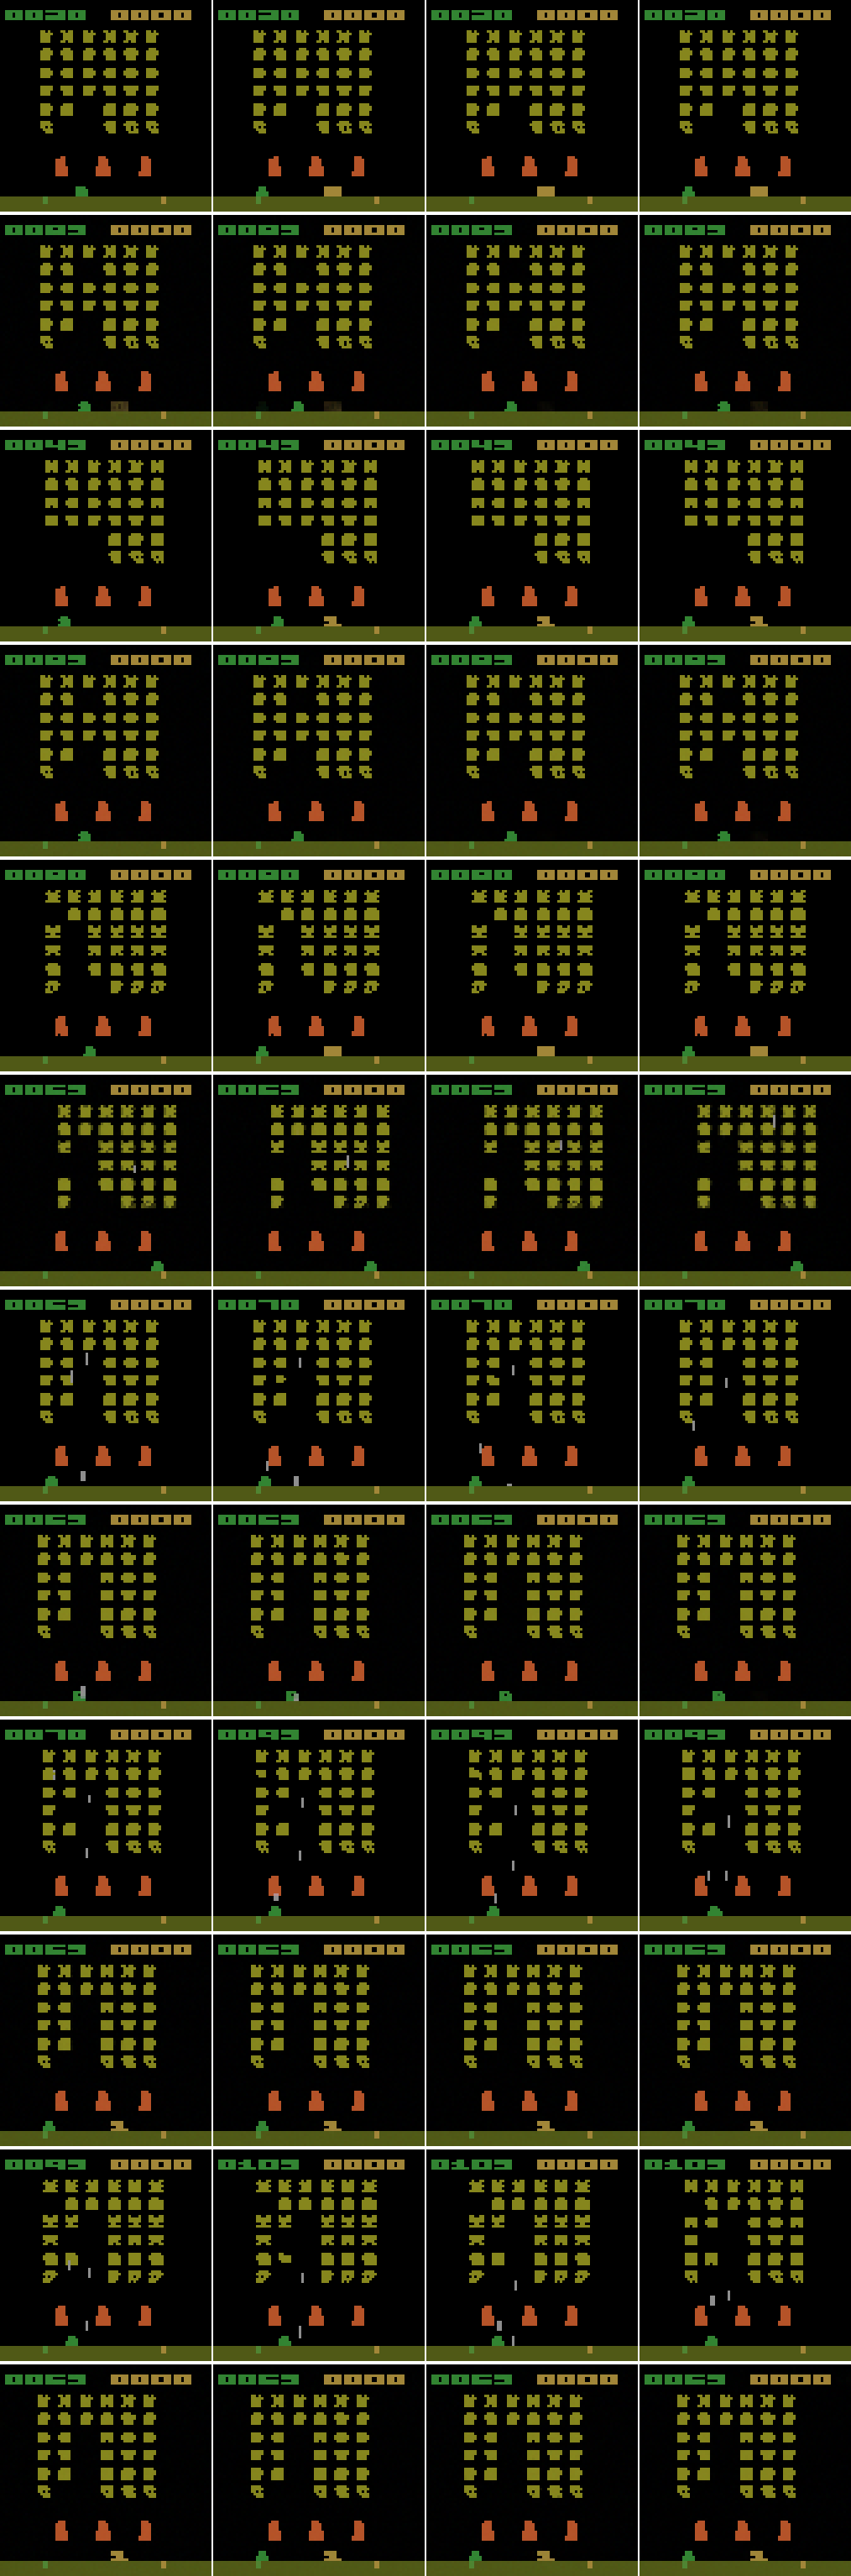

In [19]:
ev = load("e9/events.json")
d = ev["detectors"]
table(["detector vs RAM", "RAM events", "recall", "precision"],
      [["hit (score changes)", d["hits"]["ram_events"], f"{d['hits']['recall']:.2f}", f"{d['hits']['precision']:.2f}"],
       ["life lost (explosion)", d["deaths"]["ram_events"], f"{d['deaths']['recall']:.2f}", f"{d['deaths']['precision']:.2f}"]])
print(f"alien count vs RAM invaders left: correlation {d['alien_count_vs_ram_corr']:.3f}")

name = lambda k: k.split("_m2_")[1].split("_ckpt")[0] if "_m2_" in k else ("final" if "final" in k else k)
models = {name(k): v for k, v in ev["models"].items()}
steps = len(ev["trajectories"]) * ev["T"]
w = 2 * ev["match_window"] + 1

def chance(v):
    """Recall a model would get by luck: P(at least one of its events falls in a real event's window)."""
    return 1 - (1 - v["generated"] / steps) ** w

rows = []
for n, v in models.items():
    h, dth = v["hits"], v["deaths"]
    rows.append([n, f"{h['recall']:.0%} ({round(h['recall'] * h['real'])}/{h['real']})", f"{chance(h):.0%}",
                 f"{h['false_per_100_steps']:.2f}", f"{round(dth['recall'] * dth['real'])}/{dth['real']}",
                 f"{dth['false_per_100_steps'] * steps / 100:.0f}"])
table(["model", "hits reproduced", "by chance", "invented hits per 100 steps", "deaths reproduced",
       "invented deaths"], rows)
hs = list(next(iter(models.values()))["alien_abs_error"])
table(["model"] + [f"alien error h={h}" for h in hs] + [f"player x error h={h}" for h in ("20", "100", "200")],
      [[n] + [f"{v['alien_abs_error'][h]:.1f}" for h in hs] + [f"{v['player_x_abs_error'][h]:.1f}" for h in ("20", "100", "200")]
       for n, v in models.items()])
print(f"{steps:,} generated steps per model; alien error in aliens, player x error in pixels (84 px wide frame)")
display(Image(filename=str(RESULTS / "e9/events_examples.png"), width=520))

Figure (final model): missed deaths, then missed hits. Each pair of rows is real (top) and generated (bottom), at
steps t-1, t, t+2 and t+5 around the real event.

Result: the models don't reproduce the consequences of the player's actions.
- Hits: the final model reproduces 45% of the 494 real hits. Its score changes would match only 16% by chance, so it
  does learn when a shot connects. R0's 34% is no better than chance (36%), because it invents score changes all
  the time (6.8 per 100 steps). X1 almost never changes the score (4 times in 12,800 steps): context noise teaches
  it to keep the score stable, but also to ignore real changes. In the figure the generated score stays the same
  and the hit alien often lingers.
- Deaths: no model reproduces life losses. The final model gets 2 of 37 and the others none; the generated player
  just keeps going, as in the top rows of the figure. A life loss is the rarest event (37 in 12,800 steps).
- Aliens: the final model counts aliens best at short horizons (0.5 aliens off at h = 5). R0 drifts the most: 9.6
  aliens off at h = 200, worse than copy-last's 5.8, because it adds and removes aliens. X1 and the final model stay
  within about 3 aliens at h = 200.
- The ship follows the actions: its position error stays at 0.2 px or less up to h = 20 for every model, against
  6.9 px for copy-last.
- In short, the models get control right and consequences (scoring, dying) wrong. These are rare events that
  change only a few pixels, so the denoising loss gives them little weight. They are what the final failure gallery
  and any event-weighted loss should target.

### Memorization check
A diffusion model can leak training data by reproducing training frames. For generated frames at h = 1, 20 and 50
(64 trajectories each) we searched all 4.7M training frames for the nearest one (pixel RMSE on a 0-255 scale), and
did the same for the real frames at the same steps as a reference. A memorizing model would produce frames that are
closer to the training set than real held-out frames are. A "copy" is a frame within RMSE 1 of a training frame.

| model | h | generated: nearest training frame | real: nearest training frame | generated copies | real copies | generated vs its own target |
|---|---|---|---|---|---|---|
| final | 1 | 1.09 | 0.00 | 14% | 92% | 1.09 |
| final | 20 | 4.24 | 1.46 | 2% | 38% | 6.86 |
| final | 50 | 5.34 | 4.49 | 0% | 14% | 22.13 |
| r0 | 1 | 2.86 | 0.00 | 0% | 92% | 2.86 |
| r0 | 20 | 10.17 | 1.46 | 0% | 38% | 25.79 |
| r0 | 50 | 10.91 | 4.49 | 0% | 14% | 39.86 |
| x1_aug | 1 | 2.70 | 0.00 | 0% | 92% | 2.70 |
| x1_aug | 20 | 5.14 | 1.46 | 0% | 38% | 20.27 |
| x1_aug | 50 | 5.69 | 4.49 | 0% | 14% | 20.96 |

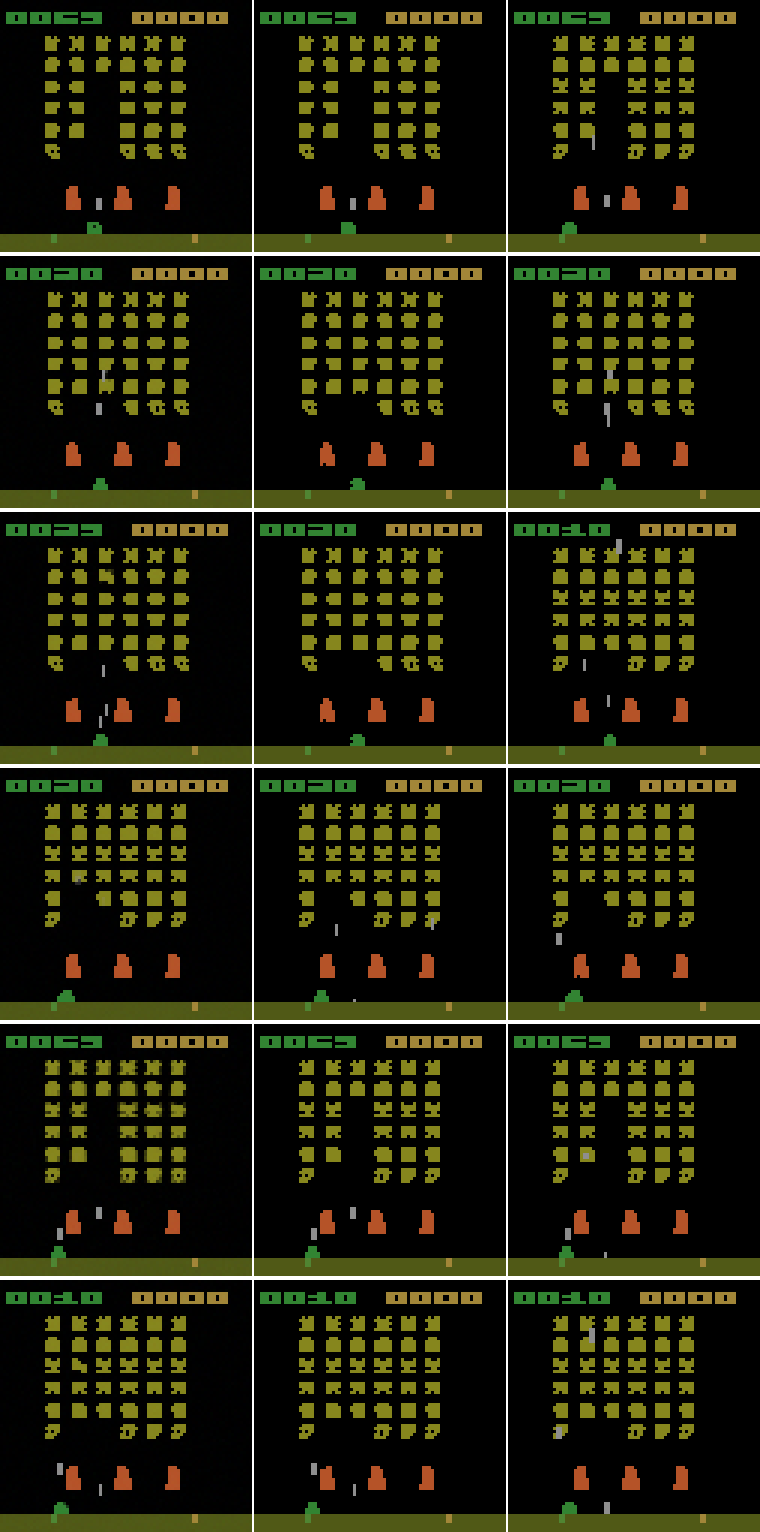

In [20]:
nn = load("e9/nn.json")
rows = []
for k, v in nn["models"].items():
    for h, r in v.items():
        g, re_ = r["generated"], r["real"]
        rows.append([name(k), h, f"{g['median_nn_rmse']:.2f}", f"{re_['median_nn_rmse']:.2f}", f"{g['copies']:.0%}",
                     f"{re_['copies']:.0%}", f"{np.median(g['target_rmse']):.2f}"])
table(["model", "h", "generated: nearest training frame", "real: nearest training frame", "generated copies",
       "real copies", "generated vs its own target"], rows)
display(Image(filename=str(RESULTS / "e9/nn_examples.png"), width=420))

Figure (final model, h = 50): generated | nearest training frame | real target.

Result: no memorization.
- Generated frames are never closer to the training set than real held-out frames. It is the real frames that have
  exact copies: 92% at h = 1 and 14% at h = 50, because every game starts from the same screen and the training set
  covers the early game densely (section 2). The final model's frames are copies only at h = 1 (14%), where its
  prediction is nearly the real target (RMSE 1.1).
- When the model drifts, it drifts to plausible states. At h = 50 the final model's frames are about as close to
  some training frame (median 5.3) as real frames are (4.5), but far from their own target (22). So the model ends
  up in a different but realistic game state, not in garbage and not in a copied frame. In the figure the generated
  frame keeps aliens the real game has lost, and the closest training frame has the same formation.
- Context noise keeps frames realistic. R0's frames are twice as far from any real frame (10.9 at h = 50) as X1's
  (5.7) or the final model's. Without augmentation, errors pile up and leave the space of real game screens; with it,
  the model stays there. This is the same effect behind X1's rollout gains in E8.
- One failure is visible in the figure: a double exposure of the alien formation while it shifts (row 5).

## 7. Plan for the final submission
Finishing touches only, with no new architectures, datasets or large searches:
1. Failure gallery for the final model on `data/eval`: drift, vanished or duplicated aliens, and missing lasers,
   next to the E9 event examples.
2. Sampling steps on the final model (1, 2, 3, 5, 10), inference only on `data/eval`, to confirm that 2 steps is
   still the right choice for the larger model.
3. Speed table: generated frames per second for the final model on a GPU and on a laptop, for the playable demo.
4. Finish the playable demo from our project plan, using the final model at 2 steps and context level 0.
5. Address the Milestone 2 feedback.
6. Clean up the notebook (Restart and Run All, labelled figures, no dead cells) and write short conclusions and
   limitations: rare events are missed, rollouts drift after about 50 steps, and controllability is only measured
   on the ship.
7. The test set stays untouched; the final numbers are the ones in section 5.